<a href="https://colab.research.google.com/github/22youl/100J/blob/main/Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **[과제3] 특성 공학(Feature Engineering) 파이프라인 구현 및 성능 비교 실험**

***데이터 셋 = Titanic Dataset***

# **STEP 01. 데이터 준비**

**1. 데이터 불러오기**

**Colab에서 titanic.zip 파일을 선택하여 업로드합니다.**

In [ ]:
import io
import zipfile

import pandas as pd
from google.colab import files
from IPython.display import display

# 1) Colab에 Titanic ZIP 파일 업로드
uploaded = files.upload()

zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_names:
    raise ValueError("titanic.zip 파일을 업로드해 주세요.")

zip_name = zip_names[0]

# 2) 압축 파일 안의 데이터 목록 확인 및 학습 데이터 불러오기
with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as zip_file:
    file_names = zip_file.namelist()
    print("ZIP 내부 파일:", file_names)

    train_files = [
        name for name in file_names
        if name.split("/")[-1].lower() == "train.csv"
    ]
    if not train_files:
        raise FileNotFoundError("ZIP에서 train.csv를 찾지 못했습니다.")

    df = pd.read_csv(zip_file.open(train_files[0]))

print("학습 데이터 불러오기 완료!")
print("데이터 shape:", df.shape)

Saving titanic.zip to titanic (1).zip
ZIP 내부 파일: ['gender_submission.csv', 'test.csv', 'train.csv']
학습 데이터 불러오기 완료!
데이터 shape: (891, 12)


**2. 데이터 기본 구조 확인**

**처음 5개 행, 전체 컬럼과 데이터 타입, 결측값 개수를 확인합니다.**

In [ ]:
# 데이터 앞부분 확인
display(df.head())

# 전체 구조와 자료형 확인
print("\n[데이터 정보]")
df.info()

print("\n[컬럼 이름]")
print(df.columns.tolist())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



[데이터 정보]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

[컬럼 이름]
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


**3. 데이터 셋 소개**

| 항목 | 내용 |
|---|---|
| 데이터셋명 | Titanic — Machine Learning from Disaster |
| 데이터 출처 | Kaggle 공개 데이터셋 |
| 데이터 내용 | 타이타닉호 승객의 객실 등급, 성별, 나이, 가족 동승 수, 운임 등 정보와 생존 여부 |
| 사용 파일 | `train.csv` |
| 전체 데이터 크기 | **891행 × 12열** (업로드 데이터 기준) |
| 지도학습 유형 | **이진 분류(Binary Classification)** |
| 타깃 변수 | **`Survived`** |
| 타깃 값 | 0 = 사망(비생존), 1 = 생존 |
| 수치형 변수 예시 | `Age`, `Fare`, `SibSp`, `Parch` |
| 범주형 변수 예시 | `Sex`, `Pclass`, `Embarked` |

**4. 컬럼 설명 표**

**컬럼 이름과 실제 자료형, 의미, 변수 분류, 결측값 개수를 표로 출력합니다.**

In [ ]:
# 컬럼별 의미 및 분석 시 역할
column_info = {
    "PassengerId": ("승객 식별 번호", "식별자"),
    "Survived": ("생존 여부 (0=사망, 1=생존)", "타깃(범주형)"),
    "Pclass": ("객실 등급 (1=1등석, 2=2등석, 3=3등석)", "범주형(정수 코드)"),
    "Name": ("승객 이름", "문자열"),
    "Sex": ("승객 성별", "범주형"),
    "Age": ("승객 나이", "수치형"),
    "SibSp": ("함께 탑승한 형제자매 및 배우자 수", "수치형"),
    "Parch": ("함께 탑승한 부모 및 자녀 수", "수치형"),
    "Ticket": ("승차권 번호", "문자열/식별성"),
    "Fare": ("승차권 운임", "수치형"),
    "Cabin": ("객실 번호", "문자열/범주형"),
    "Embarked": ("승선 항구 (C=셰르부르, Q=퀸스타운, S=사우샘프턴)", "범주형"),
}

column_table = pd.DataFrame([
    {
        "컬럼명": col,
        "컬럼 설명": column_info[col][0],
        "변수 유형": column_info[col][1],
        "실제 dtype": str(df[col].dtype),
        "결측값 수": int(df[col].isna().sum()),
    }
    for col in df.columns
])

display(column_table)

,컬럼명,컬럼 설명,변수 유형,실제 dtype,결측값 수
0,PassengerId,승객 식별 번호,식별자,int64,0
1,Survived,"생존 여부 (0=사망, 1=생존)",타깃(범주형),int64,0
2,Pclass,"객실 등급 (1=1등석, 2=2등석, 3=3등석)",범주형(정수 코드),int64,0
3,Name,승객 이름,문자열,object,0
4,Sex,승객 성별,범주형,object,0
5,Age,승객 나이,수치형,float64,177
6,SibSp,함께 탑승한 형제자매 및 배우자 수,수치형,int64,0
7,Parch,함께 탑승한 부모 및 자녀 수,수치형,int64,0
8,Ticket,승차권 번호,문자열/식별성,object,0
9,Fare,승차권 운임,수치형,float64,0


**5. 수치형·범주형 변수 및 타깃 정의**

In [ ]:
# 타깃(y)과 설명 변수(X) 정의
target_column = "Survived"
y = df[target_column]
X = df.drop(columns=[target_column])

numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

print("[타깃 변수]", target_column)
print("[수치형 변수]", numeric_features)
print("[범주형 변수]", categorical_features)
print("[설명 변수 X shape]", X.shape)
print("[타깃 y shape]", y.shape)

print("\n[타깃 값별 샘플 수]")
print(y.value_counts().sort_index().rename(index={0: "0: 사망", 1: "1: 생존"}))

[타깃 변수] Survived
[수치형 변수] ['Age', 'SibSp', 'Parch', 'Fare']
[범주형 변수] ['Pclass', 'Sex', 'Embarked']
[설명 변수 X shape] (891, 11)
[타깃 y shape] (891,)

[타깃 값별 샘플 수]
Survived
0: 사망    549
1: 생존    342
Name: count, dtype: int64


**6. 데이터 shape 출력**

In [ ]:
print("=" * 45)
print("STEP 01 - 데이터 shape 출력 결과")
print("=" * 45)
print(f"행(샘플) 수: {df.shape[0]}")
print(f"열(컬럼) 수: {df.shape[1]}")
print(f"데이터 shape: {df.shape}")
print(f"타깃 변수: {target_column}")
print(f"500개 이상 조건 충족: {len(df) >= 500}")
print(f"수치형 변수 포함: {len(numeric_features) > 0}")
print(f"범주형 변수 포함: {len(categorical_features) > 0}")

STEP 01 - 데이터 shape 출력 결과
행(샘플) 수: 891
열(컬럼) 수: 12
데이터 shape: (891, 12)
타깃 변수: Survived
500개 이상 조건 충족: True
수치형 변수 포함: True
범주형 변수 포함: True


**7. 결측값 확인**

In [ ]:
missing_table = pd.DataFrame({
    "컬럼명": df.columns,
    "결측값 수": df.isna().sum().values,
    "결측 비율(%)": (df.isna().mean() * 100).round(2).values,
})

display(missing_table[missing_table["결측값 수"] > 0])

,컬럼명,결측값 수,결측 비율(%)
5,Age,177,19.87
10,Cabin,687,77.10
11,Embarked,2,0.22


# **STEP 02. 탐색적 데이터 분석(EDA)**

**0. 데이터 불러오기**

앞 단계와 같은 train.csv를 사용합니다.

In [ ]:
from pathlib import Path
import io
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# 이전 단계에서 df를 불러왔다면 재사용
if "df" in globals() and isinstance(df, pd.DataFrame) and "Survived" in df.columns:
    df = df.copy()
    print("STEP 01에서 불러온 df를 재사용합니다.")
else:
    # Colab 실행 폴더에 있는 ZIP/CSV 파일 우선 사용
    zip_paths = [Path("titanic.zip"), Path("/content/titanic.zip")]
    csv_paths = [Path("train.csv"), Path("/content/train.csv")]
    zip_path = next((p for p in zip_paths if p.is_file()), None)
    csv_path = next((p for p in csv_paths if p.is_file()), None)

    if zip_path:
        with zipfile.ZipFile(zip_path) as zf:
            train_path = next((n for n in zf.namelist()
                               if Path(n).name.lower() == "train.csv"), None)
            if train_path is None:
                raise ValueError("ZIP 파일에서 train.csv를 찾지 못했습니다.")
            df = pd.read_csv(zf.open(train_path))
    elif csv_path:
        df = pd.read_csv(csv_path)
    else:
        # Google Colab에서는 여기서 파일 선택 창이 열립니다.
        from google.colab import files
        uploaded = files.upload()
        zip_name = next((n for n in uploaded if n.lower().endswith(".zip")), None)
        csv_name = next((n for n in uploaded if Path(n).name.lower() == "train.csv"), None)

        if zip_name:
            with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as zf:
                train_path = next((n for n in zf.namelist()
                                   if Path(n).name.lower() == "train.csv"), None)
                if train_path is None:
                    raise ValueError("ZIP 파일에 train.csv가 없습니다.")
                df = pd.read_csv(zf.open(train_path))
        elif csv_name:
            df = pd.read_csv(io.BytesIO(uploaded[csv_name]))
        else:
            raise ValueError("titanic.zip 또는 train.csv를 업로드하세요.")

assert "Survived" in df.columns, "Survived 컬럼이 있어야 합니다."
print(f"데이터 shape: {df.shape}")
display(df.head())

STEP 01에서 불러온 df를 재사용합니다.
데이터 shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**1. 데이터 기본 구조 확인**

**전체 데이터의 행·열 개수, 컬럼 자료형, 데이터 중복 여부를 확인합니다.**

In [ ]:
print("[데이터 형태]", df.shape)
print("[전체 중복 행 수]", df.duplicated().sum())
print("\n[컬럼별 데이터 타입]")
display(df.dtypes.to_frame(name="dtype"))
print("\n[수치형 변수 요약 통계]")
display(df[["Age", "Fare", "SibSp", "Parch"]].describe().round(2))

[데이터 형태] (891, 12)
[전체 중복 행 수] 0

[컬럼별 데이터 타입]


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64



[수치형 변수 요약 통계]


,Age,Fare,SibSp,Parch
count,714.00,891.00,891.00,891.00
mean,29.70,32.20,0.52,0.38
std,14.53,49.69,1.10,0.81
min,0.42,0.00,0.00,0.00
25%,20.12,7.91,0.00,0.00
50%,28.00,14.45,0.00,0.00
75%,38.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


**2. 결측치 비율 분석**

결측 비율(%) = 결측값 개수 ÷ 전체 데이터 행 수 × 100

[컬럼별 결측치 분석]


,결측값 개수,결측 비율(%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


[결측값이 있는 컬럼]


,결측값 개수,결측 비율(%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


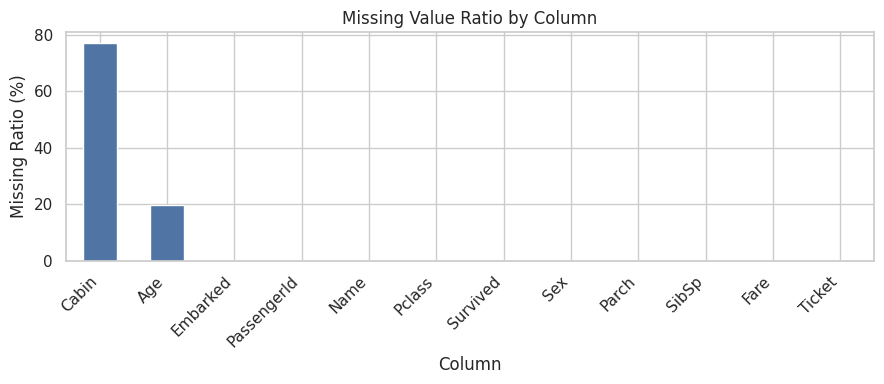

In [ ]:
missing_table = pd.DataFrame({
    "결측값 개수": df.isna().sum(),
    "결측 비율(%)": (df.isna().mean() * 100).round(2)
}).sort_values("결측 비율(%)", ascending=False)

print("[컬럼별 결측치 분석]")
display(missing_table)
print("[결측값이 있는 컬럼]")
display(missing_table.loc[missing_table["결측값 개수"] > 0])

plt.figure(figsize=(9, 4))
missing_table["결측 비율(%)"].plot(kind="bar", color="#5075a4")
plt.title("Missing Value Ratio by Column")
plt.ylabel("Missing Ratio (%)")
plt.xlabel("Column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

해석 (실제 업로드 데이터 기준)
- Age: 결측 177개(19.87%) → 중간값 대체 등을 고려할 수 있다.
- Cabin: 결측 687개(77.10%) → 결측이 매우 많아 삭제 또는 객실 정보 보유 여부 파생 변수 생성 등을 검토할 수 있다.
- Embarked: 결측 2개(0.22%) → 최빈값으로 대체하는 방법을 검토할 수 있다.


**3. Histogram — 변수 분포 시각화**

나이(Age)와 운임(Fare)의 분포를 비교합니다.

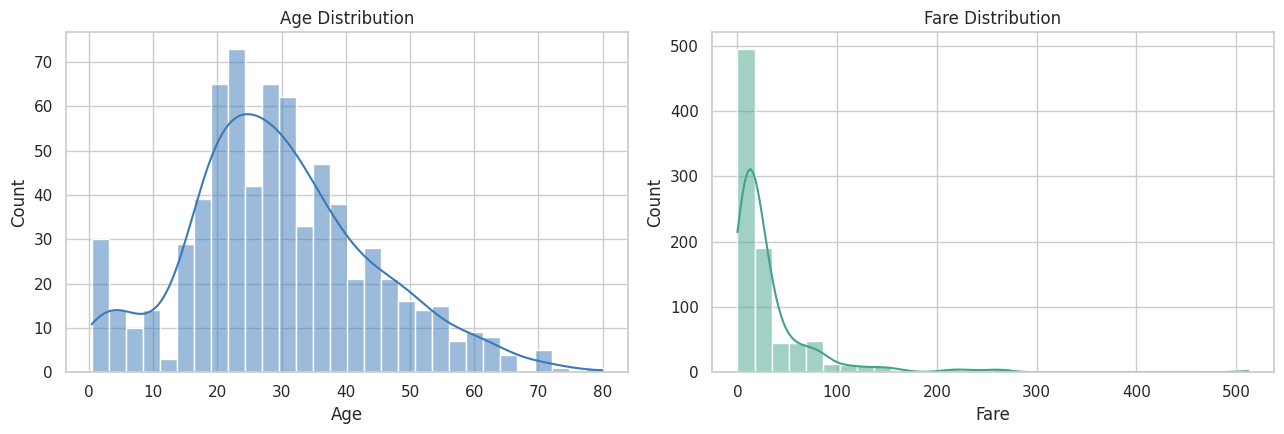

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=df, x="Age", bins=30, kde=True, ax=axes[0], color="#3b79b7")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")

sns.histplot(data=df, x="Fare", bins=30, kde=True, ax=axes[1], color="#44a28c")
axes[1].set_title("Fare Distribution")
axes[1].set_xlabel("Fare")

plt.tight_layout()
plt.show()

분포 해석

- 나이는 주로 성인 연령대에 몰려 있다. 운임(Fare)은 낮은 값에 많이 집중되어 있고, 일부 매우 높은 운임 때문에 오른쪽으로 긴 꼬리를 갖는 분포다.

**4. Boxplot — 이상치 탐색**

Boxplot과 IQR 방법을 함께 사용합니다.

IQR = Q3 − Q1 / 이상치 경계: Q1 − 1.5×IQR, Q3 + 1.5×IQR

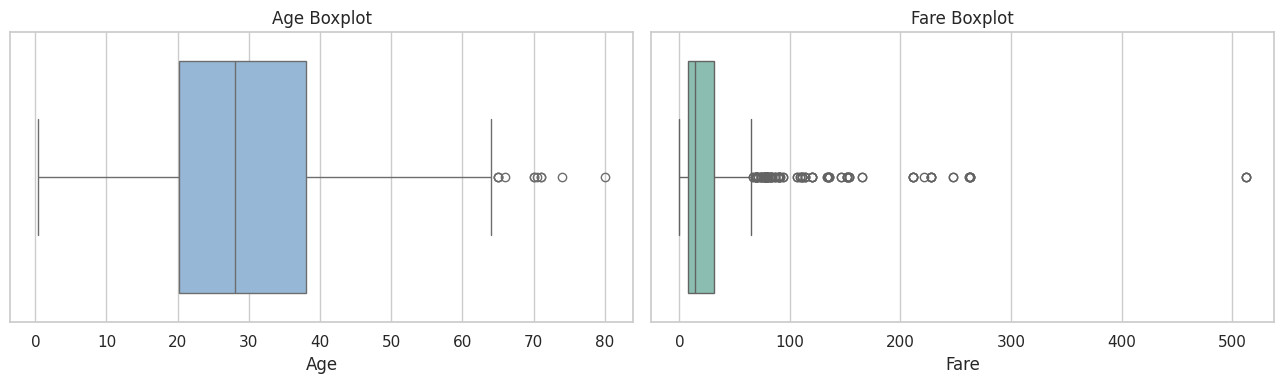

[IQR 기준 이상치 현황]


,변수,Q1,Q3,IQR,하한,상한,이상치 개수,비율(관측치 대비 %)
0,Age,20.12,38.0,17.88,-6.69,64.81,11,1.54
1,Fare,7.91,31.0,23.09,-26.72,65.63,116,13.02


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=df, x="Age", ax=axes[0], color="#8bb9e1")
axes[0].set_title("Age Boxplot")

sns.boxplot(data=df, x="Fare", ax=axes[1], color="#83c6b4")
axes[1].set_title("Fare Boxplot")

plt.tight_layout()
plt.show()

outlier_rows = []
for col in ["Age", "Fare"]:
    values = df[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outliers = (values < low) | (values > high)
    outlier_rows.append({
        "변수": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "하한": round(low, 2),
        "상한": round(high, 2),
        "이상치 개수": int(outliers.sum()),
        "비율(관측치 대비 %)": round(outliers.mean() * 100, 2)
    })

outlier_table = pd.DataFrame(outlier_rows)
print("[IQR 기준 이상치 현황]")
display(outlier_table)

이상치 해석
- Age는 IQR 기준 11개, Fare는 116개의 이상치가 확인된다. 단, 높은 운임은 실제 고가 객실과 연관된 정상적인 관측값일 수 있다. 따라서 이상치라는 이유만으로 삭제하지 않는다.

**5. Countplot — 범주형 및 타깃 분포 시각화**

생존 여부(Survived), 성별(Sex), 객실 등급(Pclass)의 빈도를 비교합니다.

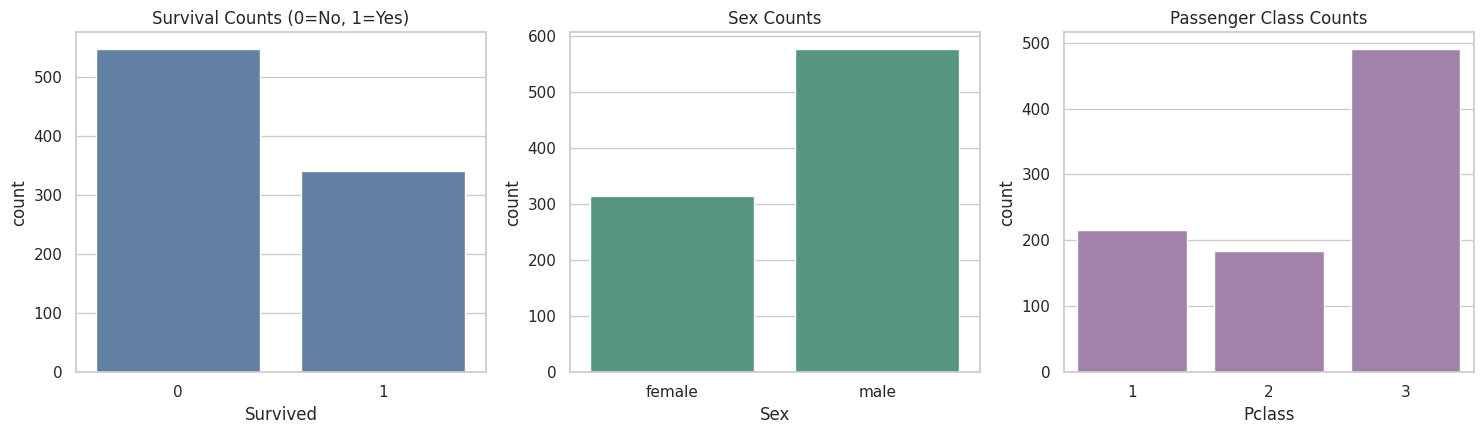

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.countplot(data=df, x="Survived", order=[0, 1], ax=axes[0], color="#577faf")
axes[0].set_title("Survival Counts (0=No, 1=Yes)")

sns.countplot(data=df, x="Sex", order=["female", "male"], ax=axes[1], color="#4c9f86")
axes[1].set_title("Sex Counts")

sns.countplot(data=df, x="Pclass", order=[1, 2, 3], ax=axes[2], color="#a57bb1")
axes[2].set_title("Passenger Class Counts")

plt.tight_layout()
plt.show()

**6. 타깃 변수 분포 및 불균형 확인**

Survived는 0 = 사망, 1 = 생존인 이진 분류 타깃입니다. 각 클래스의 개수와 비율을 계산합니다.

In [ ]:
target_counts = df["Survived"].value_counts().sort_index()
target_ratio = (df["Survived"].value_counts(normalize=True).sort_index() * 100).round(2)

target_table = pd.DataFrame({
    "생존 여부": ["사망(0)", "생존(1)"],
    "인원": target_counts.values,
    "비율(%)": target_ratio.values
})
display(target_table)

majority_rate = target_ratio.max()
print(f"다수 클래스 비율: {majority_rate:.2f}%")
print(f"클래스 개수 비율 (다수/소수): {target_counts.max()/target_counts.min():.2f}:1")
print("판단: 두 클래스의 비율이 다르므로 학습/검증 데이터 분할 시 stratify를 고려합니다.")

,생존 여부,인원,비율(%)
0,사망(0),549,61.62
1,생존(1),342,38.38


다수 클래스 비율: 61.62%
클래스 개수 비율 (다수/소수): 1.61:1
판단: 두 클래스의 비율이 다르므로 학습/검증 데이터 분할 시 stratify를 고려합니다.


**7. 주요 변수별 생존율 비교**

성별 및 객실 등급에 따른 생존율 = 해당 집단의 Survived 평균 × 100을 계산합니다.

[성별 생존율]


,승객 수,생존자 수,생존율
Sex,,,
female,314,233,74.20
male,577,109,18.89


[객실 등급별 생존율]


,승객 수,생존자 수,생존율
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


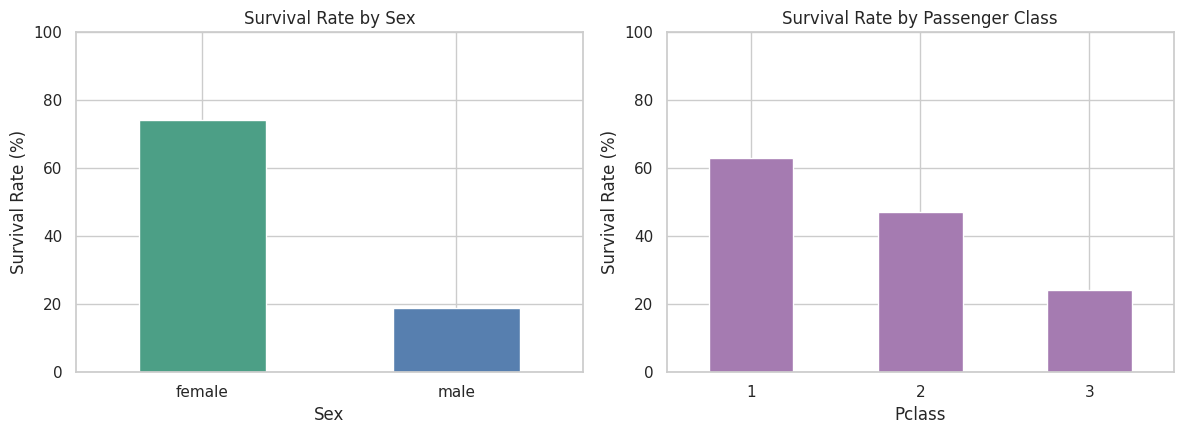

In [ ]:
sex_rate = df.groupby("Sex")["Survived"].agg(["count", "sum", "mean"])
sex_rate.columns = ["승객 수", "생존자 수", "생존율"]
sex_rate["생존율"] = (sex_rate["생존율"] * 100).round(2)

class_rate = df.groupby("Pclass")["Survived"].agg(["count", "sum", "mean"])
class_rate.columns = ["승객 수", "생존자 수", "생존율"]
class_rate["생존율"] = (class_rate["생존율"] * 100).round(2)

print("[성별 생존율]")
display(sex_rate)
print("[객실 등급별 생존율]")
display(class_rate)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sex_rate.loc[["female", "male"], "생존율"].plot(
    kind="bar", ax=axes[0], color=["#4c9f86", "#577faf"]
)
axes[0].set_title("Survival Rate by Sex")
axes[0].set_ylabel("Survival Rate (%)")
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=0)

class_rate["생존율"].plot(kind="bar", ax=axes[1], color="#a57bb1")
axes[1].set_title("Survival Rate by Passenger Class")
axes[1].set_ylabel("Survival Rate (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

생존율 해석
- 여성이 남성보다 생존 비율이 높게 나타나고, 객실 등급이 높을수록(1등석 방향) 생존 비율도 높다.

**8. Heatmap — 변수 간 상관관계 분석**

Pearson 상관계수(-1 ~ +1)를 이용합니다.

숫자로 표현된 Pclass는 원래 등급형 범주 변수임에 유의합니다.

Sex를 IsFemale(여성 1, 남성 0)로 변환해 비교하되, 이 표현 방식의 의미를 함께 해석합니다. PassengerId는 식별자이므로 제외합니다.

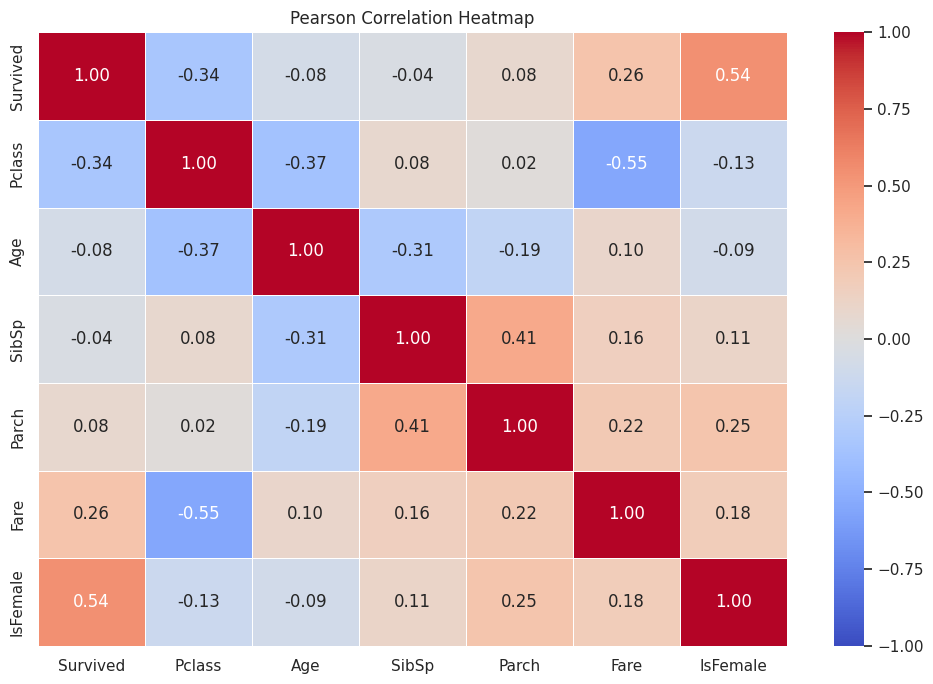

[Survived와의 상관관계]


,Survived 상관계수
IsFemale,0.5434
Fare,0.2573
Parch,0.0816
SibSp,-0.0353
Age,-0.0772
Pclass,-0.3385


In [ ]:
corr_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
corr_df["IsFemale"] = df["Sex"].map({"female": 1, "male": 0})

corr_matrix = corr_df.corr(method="pearson")
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

print("[Survived와의 상관관계]")
display(corr_matrix["Survived"].drop("Survived").sort_values(ascending=False).round(4)
        .to_frame(name="Survived 상관계수"))

상관관계 해석 (원본 데이터 기준)
- IsFemale ↔ Survived: +0.5434 (여성 지표와 생존 간 양의 상관관계)
- Pclass ↔ Survived: −0.3385 (숫자가 작을수록 높은 객실 등급이므로 음의 부호에 주의)
- Fare ↔ Survived: +0.2573 (운임과 생존 간 양의 상관관계)
- Age ↔ Survived: −0.0772 (선형 상관은 약함)
상관관계는 인과관계가 아니며, 범주형 변수와 생존 간 관계를 단일 Pearson 계수만으로 충분히 설명할 수는 없습니다.

**9. EDA 결과 요약**

① 데이터 품질 문제
- Age 177개(19.87%), Cabin 687개(77.10%), Embarked 2개(0.22%)의 결측값이 존재한다.
- 원본 데이터에 완전히 중복된 행은 0개이다.
- IQR 기준 Age 이상치 11개, Fare 이상치 116개가 확인된다. 실제 고액 운임은 유효한 관측값일 수 있으므로 무조건 삭제하지 않는다.

② 타깃 변수 불균형 여부
- 사망(Survived=0) 549명(61.62%), 생존(Survived=1) 342명(38.38%)이다.
- 클래스의 비율이 다르므로 이후 학습/검증 분할 시 층화추출(stratify)을 고려한다. 단, 심각한 불균형이라고 단정하지 않는다.

③ 주요 변수 특징
- 여성 생존율은 74.20%, 남성 생존율은 **18.89%**로 차이가 크다.
- 객실 등급별 생존율은 1등석 62.96%, 2등석 47.28%, 3등석 **24.24%**다.
- Fare는 낮은 운임에 값이 집중되고 오른쪽 꼬리가 길며 이상치로 표시된 높은 운임들이 존재한다.
- 상관관계에서 IsFemale(+0.5434), Pclass(−0.3385), Fare(+0.2573)가 Survived와 상대적으로 뚜렷한 선형 연관성을 보인다.

④ 후속 전처리 방안(제안)
- Age 결측값: 중간값 등 적절한 대체 방법 검토
- Cabin 결측값: 정보 보유 여부를 나타내는 파생변수나 제거 검토
- Embarked 결측값: 최빈값 대체 검토
- 이상치: 데이터 오류인지 확인하고, 무조건 삭제하지 않기
- 모델링: 학습 데이터 기준으로 전처리 값을 계산해 데이터 누수 방지
주의: 위 결과는 업로드한 Titanic train.csv 파일 기준이다. 사용 파일이 달라지면 수치가 달라질 수 있다.

# **STEP 03. 특성 공학 파이프라인 구현**

In [ ]:
from pathlib import Path
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from IPython.display import display

zip_path = Path("titanic.zip")

if not zip_path.exists():
    try:
        from google.colab import files
        print("titanic.zip 파일을 업로드하세요.")
        uploaded = files.upload()
        if "titanic.zip" not in uploaded:
            raise FileNotFoundError("titanic.zip 파일을 업로드해야 합니다.")
    except ImportError as exc:
        raise FileNotFoundError(
            "현재 폴더에 titanic.zip을 넣고 셀을 다시 실행하세요."
        ) from exc

with zipfile.ZipFile(zip_path) as zf:
    matches = [name for name in zf.namelist() if name.endswith("train.csv")]
    if not matches:
        raise FileNotFoundError("ZIP 파일 내부에 train.csv가 없습니다.")
    with zf.open(matches[0]) as source:
        df = pd.read_csv(source)

print("데이터 shape:", df.shape)
print("컬럼:", df.columns.tolist())
display(df.head())
print("결측값 개수:")
display(df.isna().sum().loc[lambda s: s > 0].to_frame("Missing"))

데이터 shape: (891, 12)
컬럼: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


결측값 개수:


,Missing
Age,177
Cabin,687
Embarked,2


**1. 비교 실험의 공통 조건**
- 목표값 Survived: 0 = 사망, 1 = 생존
- 입력 특성은 Age, Fare, SibSp, Parch(수치형), Pclass, Sex, Embarked(범주형) 사용
- 식별자 PassengerId, 이름 Name, 승차권 번호 Ticket, 객실 번호 Cabin은 기본 모델에서 제외합니다. 특히 Cabin은 결측 비율이 높습니다.
- Pclass가 정수로 저장되어 있어도 등급(범주형) 으로 처리합니다.
- 아래에서 만드는 파생 특성은 기존 입력값으로만 계산하므로 생존 여부는 이용하지 않습니다.

In [ ]:
BASE_NUMERIC = ["Age", "Fare", "SibSp", "Parch"]
BASE_CATEGORICAL = ["Pclass", "Sex", "Embarked"]
BASE_FEATURES = BASE_NUMERIC + BASE_CATEGORICAL

X = df[BASE_FEATURES].copy()
y = df["Survived"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

print("훈련 데이터:", X_train.shape)
print("최종 테스트 데이터:", X_test.shape)
print("훈련 타깃 비율:")
display(y_train.value_counts(normalize=True).sort_index().round(3))

훈련 데이터: (712, 7)
최종 테스트 데이터: (179, 7)
훈련 타깃 비율:


,proportion
Survived,
0,0.617
1,0.383


**2. 파생 변수 생성 함수 및 ML 파이프라인**

파생 변수 정의
- AgeGroup: 나이 구간 (Child < 13, Teen 13–17, Adult 18–59, Senior ≥ 60, Unknown)
- FamilySize: SibSp + Parch + 1 (본인 포함 가족 인원)
- FarePerPerson: Fare / FamilySize (가족 규모 대비 1인당 운임, 계산상 지표이며 실제 개인별 지불 운임과 같다는 의미는 아님)
AgeGroup의 나이 결측값은 Unknown이라는 별도 범주로 보존합니다. 결측치 처리 비교(3-1)는 기본 수치형 특성의 결측값 대체 방식을 비교합니다.

In [ ]:
def make_features(frame, engineered=()):
    """사전 지정된 수학적 규칙으로 특성을 추가합니다 (학습이 필요한 변환 없음)."""
    result = frame.copy()
    engineered = tuple(engineered)

    if "AgeGroup" in engineered:
        age_group = pd.cut(
            result["Age"],
            bins=[-np.inf, 13, 18, 60, np.inf],
            labels=["Child", "Teen", "Adult", "Senior"],
            right=False,
        )
        result["AgeGroup"] = age_group.astype(object).fillna("Unknown")

    if "FamilySize" in engineered or "FarePerPerson" in engineered:
        family_size = result["SibSp"] + result["Parch"] + 1
        if "FamilySize" in engineered:
            result["FamilySize"] = family_size
        if "FarePerPerson" in engineered:
            result["FarePerPerson"] = result["Fare"] / family_size

    return result


def build_pipeline(feature_names, numeric_imputer="median", encoder="onehot", scaler="standard"):
    """결측치 대체 / 범주 인코딩 / 스케일링을 학습 폴드 안에서만 학습합니다."""
    numeric_columns = [
        name for name in feature_names
        if name in BASE_NUMERIC or name in ["FamilySize", "FarePerPerson"]
    ]
    categorical_columns = [
        name for name in feature_names
        if name in BASE_CATEGORICAL or name == "AgeGroup"
    ]

    scale_methods = {
        "standard": StandardScaler(),
        "minmax": MinMaxScaler(),
        "robust": RobustScaler(),
    }
    encode_methods = {
        "ordinal": OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
        "onehot": OneHotEncoder(handle_unknown="ignore"),
    }

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy=numeric_imputer)),
        ("scaler", scale_methods[scaler]),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encode_methods[encoder]),
    ])
    processor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])

    return Pipeline([
        ("preprocess", processor),
        ("model", LogisticRegression(max_iter=2000, solver="liblinear")),
    ])


all_experiment_records = []


def compare_experiments(title, configs):
    """동일한 train 분할 / CV 폴드로 성능을 비교해 표를 출력합니다."""
    records = []

    for config in configs:
        setting = {
            "numeric_imputer": "median",
            "encoder": "onehot",
            "scaler": "standard",
            "engineered": (),
        }
        setting.update(config["settings"])

        features_train = make_features(X_train, setting["engineered"])
        model = build_pipeline(
            features_train.columns,
            numeric_imputer=setting["numeric_imputer"],
            encoder=setting["encoder"],
            scaler=setting["scaler"],
        )
        scores = cross_validate(
            model,
            features_train,
            y_train,
            cv=cv,
            scoring=SCORING,
            n_jobs=1,
            error_score="raise",
        )
        row = {
            "단계": title,
            "방법": config["name"],
            "CV_Accuracy": scores["test_accuracy"].mean(),
            "CV_F1": scores["test_f1"].mean(),
            "CV_ROC_AUC": scores["test_roc_auc"].mean(),
            "CV_AUC_Std": scores["test_roc_auc"].std(),
            "config": setting,
        }
        records.append(row)
        all_experiment_records.append(row)

    result = pd.DataFrame(records).sort_values("CV_ROC_AUC", ascending=False)
    print("■", title)
    display(result.drop(columns="config").round(4))

    ax = result.sort_values("CV_ROC_AUC").plot.barh(
        x="방법",
        y="CV_ROC_AUC",
        legend=False,
        figsize=(8, max(2.6, 0.55 * len(result) + 1)),
    )
    ax.set_xlabel("5-fold mean ROC-AUC")
    ax.set_ylabel("")
    ax.set_title(title)
    ax.set_xlim(0.65, 1.0)
    plt.tight_layout()
    plt.show()
    return result

print("비교용 공통 LogisticRegression 파이프라인 준비 완료")

비교용 공통 LogisticRegression 파이프라인 준비 완료


**3-1. 결측치 처리 비교**

기본 변수 중 나이 Age에 결측값이 있습니다. 평균 / 중앙값 / 최빈값으로 대체하는 방법을 비교합니다. 범주형 Embarked의 결측값은 모든 실험에서 최빈값으로 동일하게 처리합니다.

■ 3-1 Missing value imputation


,단계,방법,CV_Accuracy,CV_F1,CV_ROC_AUC,CV_AUC_Std
0,3-1 Missing value imputation,Mean,0.802,0.7301,0.8536,0.0217
1,3-1 Missing value imputation,Median,0.802,0.7301,0.8533,0.0219
2,3-1 Missing value imputation,Most Frequent,0.795,0.7242,0.8517,0.0235


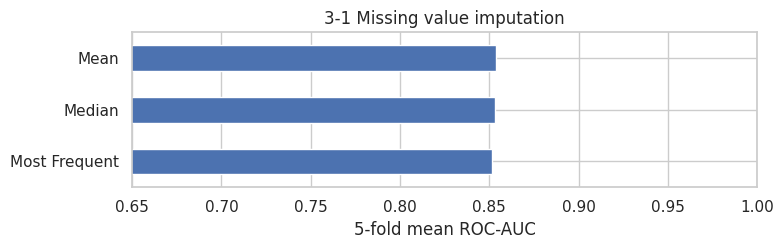

In [ ]:
imputation_results = compare_experiments(
    "3-1 Missing value imputation",
    [
        {"name": "Mean", "settings": {"numeric_imputer": "mean"}},
        {"name": "Median", "settings": {"numeric_imputer": "median"}},
        {"name": "Most Frequent", "settings": {"numeric_imputer": "most_frequent"}},
    ],
)

**3-2. 범주형 인코딩 비교**

- Ordinal(레이블형 정수 인코딩): 각 범주에 정수 코드를 부여합니다. 순서 의미가 없는 범주에 가짜 순서를 부여할 수 있습니다.
- One-Hot: 각 범주에 독립된 이진 컬럼을 부여합니다. 컬럼 수는 늘어나지만 범주 간 가짜 순서를 만들지 않습니다.

■ 3-2 Categorical encoding


,단계,방법,CV_Accuracy,CV_F1,CV_ROC_AUC,CV_AUC_Std
0,3-2 Categorical encoding,Ordinal / Label-style,0.7978,0.7242,0.8541,0.0239
1,3-2 Categorical encoding,One-Hot,0.8020,0.7301,0.8533,0.0219


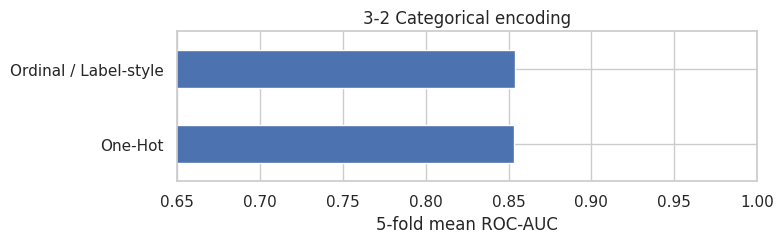

In [ ]:
encoding_results = compare_experiments(
    "3-2 Categorical encoding",
    [
        {"name": "Ordinal / Label-style", "settings": {"encoder": "ordinal"}},
        {"name": "One-Hot", "settings": {"encoder": "onehot"}},
    ],
)

**3-3. 스케일링 비교**

- StandardScaler: 평균 0, 표준편차 1을 기준으로 변환합니다.
- MinMaxScaler: 각 수치 특성을 훈련 데이터 기준으로 보통 0–1 범위로 변환합니다.
- RobustScaler: 중앙값과 사분위 범위(IQR)를 사용해 이상치에 덜 민감합니다.

■ 3-3 Numeric scaling


,단계,방법,CV_Accuracy,CV_F1,CV_ROC_AUC,CV_AUC_Std
0,3-3 Numeric scaling,StandardScaler,0.8020,0.7301,0.8533,0.0219
2,3-3 Numeric scaling,RobustScaler,0.8020,0.7301,0.8533,0.0218
1,3-3 Numeric scaling,MinMaxScaler,0.8006,0.7309,0.8520,0.0207


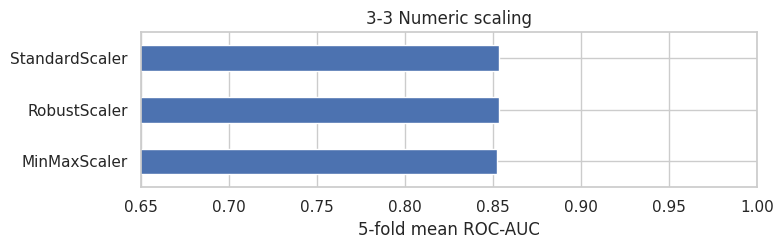

In [ ]:
scaling_results = compare_experiments(
    "3-3 Numeric scaling",
    [
        {"name": "StandardScaler", "settings": {"scaler": "standard"}},
        {"name": "MinMaxScaler", "settings": {"scaler": "minmax"}},
        {"name": "RobustScaler", "settings": {"scaler": "robust"}},
    ],
)

**3-4. 파생 변수 생성**

AgeGroup, FamilySize, FarePerPerson 3개 파생 변수를 생성하고, 원본(파생 변수 없음)과 각 변수/전체 추가 경우를 비교합니다. 나머지 설정은 Median + One-Hot + StandardScaler로 고정합니다.

파생 변수 3개가 추가된 데이터 크기: (712, 10)


,Age,AgeGroup,SibSp,Parch,FamilySize,Fare,FarePerPerson
692,NaN,Unknown,0,0,1,56.4958,56.4958
481,NaN,Unknown,0,0,1,0.0000,0.0000
527,NaN,Unknown,0,0,1,221.7792,221.7792
855,18.0,Adult,0,1,2,9.3500,4.6750
801,31.0,Adult,1,1,3,26.2500,8.7500
652,21.0,Adult,0,0,1,8.4333,8.4333
509,26.0,Adult,0,0,1,56.4958,56.4958
557,NaN,Unknown,0,0,1,227.5250,227.5250
828,NaN,Unknown,0,0,1,7.7500,7.7500
18,31.0,Adult,1,0,2,18.0000,9.0000


■ 3-4 Feature engineering


,단계,방법,CV_Accuracy,CV_F1,CV_ROC_AUC,CV_AUC_Std
3,3-4 Feature engineering,FarePerPerson only,0.8020,0.7301,0.8534,0.0217
0,3-4 Feature engineering,Baseline (no new feature),0.8020,0.7301,0.8533,0.0219
2,3-4 Feature engineering,FamilySize only,0.8020,0.7301,0.8532,0.0220
4,3-4 Feature engineering,All three,0.8034,0.7330,0.8518,0.0248
1,3-4 Feature engineering,AgeGroup only,0.8034,0.7330,0.8513,0.0246


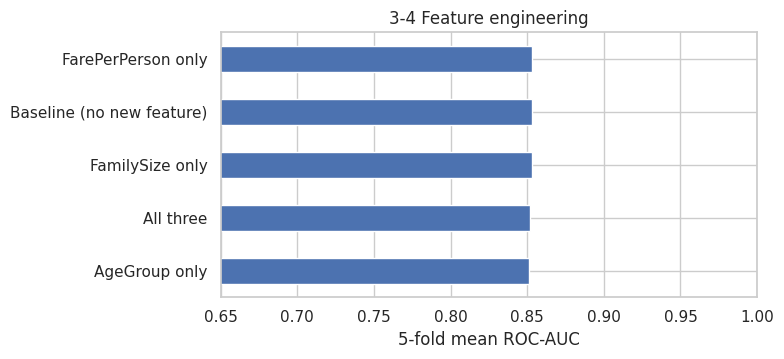

In [ ]:
derived_features = ("AgeGroup", "FamilySize", "FarePerPerson")
example_engineered = make_features(X_train, derived_features)
print("파생 변수 3개가 추가된 데이터 크기:", example_engineered.shape)
display(example_engineered[["Age", "AgeGroup", "SibSp", "Parch", "FamilySize", "Fare", "FarePerPerson"]].head(10))

feature_results = compare_experiments(
    "3-4 Feature engineering",
    [
        {"name": "Baseline (no new feature)", "settings": {"engineered": ()}},
        {"name": "AgeGroup only", "settings": {"engineered": ("AgeGroup",)}},
        {"name": "FamilySize only", "settings": {"engineered": ("FamilySize",)}},
        {"name": "FarePerPerson only", "settings": {"engineered": ("FarePerPerson",)}},
        {"name": "All three", "settings": {"engineered": derived_features}},
    ],
)

**4. 전체 비교 결과 요약 및 최종 테스트 평가**

- 먼저 훈련 데이터에서 얻은 CV ROC-AUC로 앞의 실험 후보 중 최고 조합을 고릅니다. 그 다음 선택된 파이프라인을 전체 훈련 데이터에 학습하여 한 번만 최종 테스트에 평가합니다.
- 주의: 실험마다 다른 항목은 한 가지씩만 바꿨으므로, 서로의 최적값을 조합한 모든 가능한 경우를 탐색한 것은 아닙니다. CV 점수 차이가 작다면 성능 차이가 안정적이라고 단정할 수 없습니다.

■ 전체 실험 순위 (상위 10개)


,단계,방법,CV_Accuracy,CV_F1,CV_ROC_AUC,CV_AUC_Std
3,3-2 Categorical encoding,Ordinal / Label-style,0.7978,0.7242,0.8541,0.0239
0,3-1 Missing value imputation,Mean,0.8020,0.7301,0.8536,0.0217
11,3-4 Feature engineering,FarePerPerson only,0.8020,0.7301,0.8534,0.0217
4,3-2 Categorical encoding,One-Hot,0.8020,0.7301,0.8533,0.0219
1,3-1 Missing value imputation,Median,0.8020,0.7301,0.8533,0.0219
8,3-4 Feature engineering,Baseline (no new feature),0.8020,0.7301,0.8533,0.0219
5,3-3 Numeric scaling,StandardScaler,0.8020,0.7301,0.8533,0.0219
7,3-3 Numeric scaling,RobustScaler,0.8020,0.7301,0.8533,0.0218
10,3-4 Feature engineering,FamilySize only,0.8020,0.7301,0.8532,0.0220
6,3-3 Numeric scaling,MinMaxScaler,0.8006,0.7309,0.8520,0.0207


최종 선택 단계: 3-2 Categorical encoding
최종 선택 방법: Ordinal / Label-style
최고 훈련 CV ROC-AUC: 0.8541
선택된 파이프라인 설정: {'numeric_imputer': 'median', 'encoder': 'ordinal', 'scaler': 'standard', 'engineered': ()}

■ 최종 홀드아웃 테스트 결과
Accuracy: 0.8045
F1-score: 0.7244
ROC-AUC: 0.8506

분류 리포트
              precision    recall  f1-score   support

    Died (0)       0.81      0.89      0.85       110
Survived (1)       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



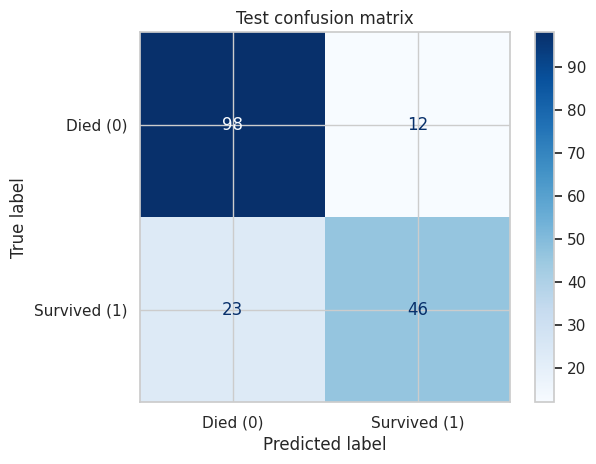

In [ ]:
summary = pd.DataFrame(all_experiment_records).drop(columns="config")
summary = summary.sort_values("CV_ROC_AUC", ascending=False)
print("■ 전체 실험 순위 (상위 10개)")
display(summary.head(10).round(4))

best_row = max(all_experiment_records, key=lambda row: row["CV_ROC_AUC"])
best_config = best_row["config"]

print("최종 선택 단계:", best_row["단계"])
print("최종 선택 방법:", best_row["방법"])
print("최고 훈련 CV ROC-AUC:", round(best_row["CV_ROC_AUC"], 4))
print("선택된 파이프라인 설정:", best_config)

X_train_final = make_features(X_train, best_config["engineered"])
X_test_final = make_features(X_test, best_config["engineered"])

final_model = build_pipeline(
    X_train_final.columns,
    numeric_imputer=best_config["numeric_imputer"],
    encoder=best_config["encoder"],
    scaler=best_config["scaler"],
)
final_model.fit(X_train_final, y_train)
y_pred = final_model.predict(X_test_final)
y_prob = final_model.predict_proba(X_test_final)[:, 1]

print("\n■ 최종 홀드아웃 테스트 결과")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\n분류 리포트")
print(classification_report(y_test, y_pred, target_names=["Died (0)", "Survived (1)"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Died (0)", "Survived (1)"],
    cmap="Blues", values_format="d"
)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()

**5. 분석 결과 및 요약**

In [ ]:
def top_method(table):
    best = table.iloc[0]
    return best["방법"], best["CV_ROC_AUC"]

best_imp = top_method(imputation_results)
best_enc = top_method(encoding_results)
best_scaler = top_method(scaling_results)
best_feature = top_method(feature_results)

print("=" * 72)
print("STEP 03 특성 공학 파이프라인 실험 결과")
print("=" * 72)
print(f"3-1 결측치 처리: {best_imp[0]} (CV ROC-AUC={best_imp[1]:.4f})")
print(f"3-2 범주형 인코딩: {best_enc[0]} (CV ROC-AUC={best_enc[1]:.4f})")
print(f"3-3 스케일링: {best_scaler[0]} (CV ROC-AUC={best_scaler[1]:.4f})")
print(f"3-4 파생 변수: {best_feature[0]} (CV ROC-AUC={best_feature[1]:.4f})")
print("생성한 파생 변수: AgeGroup, FamilySize, FarePerPerson (3개)")
print(f"최종 테스트: Accuracy={accuracy_score(y_test, y_pred):.4f}, "
      f"F1={f1_score(y_test, y_pred):.4f}, ROC-AUC={roc_auc_score(y_test, y_prob):.4f}")
print("※ CV는 훈련 데이터로만 수행했고, 최종 테스트는 모델 선택에 사용하지 않았습니다.")
print("※ 성능 차이가 작으면 우열이 명확하지 않을 수 있으며, 일반화 성능을 보장하지 않습니다.")

export = summary.copy().round(5)
export.to_csv("Titanic_STEP03_실험_결과.csv", index=False, encoding="utf-8-sig")
print("실험 결과 CSV 저장 완료: Titanic_STEP03_실험_결과.csv")

STEP 03 특성 공학 파이프라인 실험 결과
3-1 결측치 처리: Mean (CV ROC-AUC=0.8536)
3-2 범주형 인코딩: Ordinal / Label-style (CV ROC-AUC=0.8541)
3-3 스케일링: StandardScaler (CV ROC-AUC=0.8533)
3-4 파생 변수: FarePerPerson only (CV ROC-AUC=0.8534)
생성한 파생 변수: AgeGroup, FamilySize, FarePerPerson (3개)
최종 테스트: Accuracy=0.8045, F1=0.7244, ROC-AUC=0.8506
※ CV는 훈련 데이터로만 수행했고, 최종 테스트는 모델 선택에 사용하지 않았습니다.
※ 성능 차이가 작으면 우열이 명확하지 않을 수 있으며, 일반화 성능을 보장하지 않습니다.
실험 결과 CSV 저장 완료: Titanic_STEP03_실험_결과.csv


# **STEP 04. 변수 선택**

In [ ]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel, SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

SEED = 42
TOP_N = 5
K_CANDIDATES = [3, 5, 7]

zip_path = Path("titanic.zip")
if not zip_path.exists() and Path("/mnt/data/titanic.zip").exists():
    zip_path = Path("/mnt/data/titanic.zip")

if not zip_path.exists():
    try:
        from google.colab import files
        print("titanic.zip 파일을 업로드하세요.")
        uploaded = files.upload()
        if "titanic.zip" not in uploaded:
            raise FileNotFoundError("titanic.zip 파일을 업로드해야 합니다.")
        zip_path = Path("titanic.zip")
    except ImportError as exc:
        raise FileNotFoundError("titanic.zip을 현재 작업 폴더에 넣어주세요.") from exc

with zipfile.ZipFile(zip_path) as zf:
    matches = [name for name in zf.namelist() if Path(name).name == "train.csv"]
    if not matches:
        raise FileNotFoundError("titanic.zip 내부에서 train.csv를 찾지 못했습니다.")
    with zf.open(matches[0]) as source:
        df = pd.read_csv(source)

required = ["Age", "Fare", "SibSp", "Parch", "Pclass", "Sex", "Embarked", "Survived"]
missing_columns = [column for column in required if column not in df.columns]
if missing_columns:
    raise ValueError(f"필수 컬럼이 없습니다: {missing_columns}")

print("데이터 shape:", df.shape)
print("생존 여부 분포:")
display(df["Survived"].value_counts().rename(index={0: "사망(0)", 1: "생존(1)"}).to_frame("Count"))
display(df.head(3))

데이터 shape: (891, 12)
생존 여부 분포:


,Count
Survived,
사망(0),549
생존(1),342


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


**1. STEP 03 파생 변수 생성 및 훈련/테스트 데이터 분리**

- AgeGroup: Child(13세 미만), Teen(13–17세), Adult(18–59세), Senior(60세 이상), Unknown(결측)
- FamilySize: SibSp + Parch + 1 (승객 자신 포함 동승 가족 규모)
- FarePerPerson: Fare / FamilySize (가족 규모 대비 운임을 나눈 계산상 지표)
원본 7개 특성 + 파생 3개 특성 = 총 10개 원본 수준의 입력 변수입니다. Survived는 특성 생성 및 선택 입력에 포함하지 않습니다.

In [ ]:
BASE_NUMERIC = ["Age", "Fare", "SibSp", "Parch"]
BASE_CATEGORICAL = ["Pclass", "Sex", "Embarked"]
DERIVED_NUMERIC = ["FamilySize", "FarePerPerson"]
DERIVED_CATEGORICAL = ["AgeGroup"]
NUMERIC_FEATURES = BASE_NUMERIC + DERIVED_NUMERIC
CATEGORICAL_FEATURES = BASE_CATEGORICAL + DERIVED_CATEGORICAL
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES


def make_features(frame):
    """입력 특성만을 사용하여 결정론적 파생 특성 3개를 생성합니다."""
    result = frame.copy()
    age_group = pd.cut(
        result["Age"],
        bins=[-np.inf, 13, 18, 60, np.inf],
        labels=["Child", "Teen", "Adult", "Senior"],
        right=False,
    )
    result["AgeGroup"] = age_group.astype(object).fillna("Unknown")
    result["FamilySize"] = result["SibSp"] + result["Parch"] + 1
    result["FarePerPerson"] = result["Fare"] / result["FamilySize"]
    return result


X = make_features(df[BASE_NUMERIC + BASE_CATEGORICAL])[ALL_FEATURES]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

print("전체 특성 수:", X.shape[1])
print("전체 특성:", ALL_FEATURES)
print("훈련 크기:", X_train.shape, "테스트 크기:", X_test.shape)
display(X_train.head())

전체 특성 수: 10
전체 특성: ['Age', 'Fare', 'SibSp', 'Parch', 'FamilySize', 'FarePerPerson', 'Pclass', 'Sex', 'Embarked', 'AgeGroup']
훈련 크기: (712, 10) 테스트 크기: (179, 10)


,Age,Fare,SibSp,Parch,FamilySize,FarePerPerson,Pclass,Sex,Embarked,AgeGroup
692,NaN,56.4958,0,0,1,56.4958,3,male,S,Unknown
481,NaN,0.0000,0,0,1,0.0000,2,male,S,Unknown
527,NaN,221.7792,0,0,1,221.7792,1,male,S,Unknown
855,18.0,9.3500,0,1,2,4.6750,3,female,S,Adult
801,31.0,26.2500,1,1,3,8.7500,2,female,S,Adult


**2. 공통 전처리 및 모델 구성**

- 제거 전 기준 모델: 10개 변수 전체 사용.

- 선택 모델: 전처리 후에 변수 선택기를 적용하되, 반드시 교차검증 Pipeline 안에서 변수 중요도 또는 통계량을 학습합니다. 여기서는 범주형을 정수 코드로 치환하므로 인코딩한 각 범주형 특성이 하나의 컬럼에 대응하여 선택 결과를 쉽게 해석할 수 있습니다. 다만 순서가 없는 범주에 인위적 순서가 생길 수 있는 한계가 있습니다.

In [ ]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, NUMERIC_FEATURES),
        ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
    ], remainder="drop")


def make_estimator(selection_method=None, n_features=None):
    steps = [("preprocess", make_preprocessor())]
    if selection_method == "Random Forest Importance":
        steps.append(("selector", SelectFromModel(
            estimator=RandomForestClassifier(
                n_estimators=100,
                min_samples_leaf=2,
                random_state=SEED,
                n_jobs=1,
            ),
            threshold=-np.inf,
            max_features=n_features,
        )))
    elif selection_method == "SelectKBest":
        steps.append(("selector", SelectKBest(score_func=f_classif, k=n_features)))
    elif selection_method is not None:
        raise ValueError(f"알 수 없는 선택 방법: {selection_method}")

    steps.append(("model", LogisticRegression(max_iter=2500, random_state=SEED)))
    return Pipeline(steps)


def clean_feature_name(name):
    return name.split("__", 1)[-1]


baseline = make_estimator()
print("비교에 사용할 모델:", baseline.named_steps["model"].__class__.__name__)
print("변수 선택 방법: Random Forest Importance / SelectKBest")

비교에 사용할 모델: LogisticRegression
변수 선택 방법: Random Forest Importance / SelectKBest


**3. 선택 방법별 중요도 및 상위 N개 변수**

- Random Forest Feature Importance: 각 특성이 랜덤포레스트 불순도 감소에 기여한 상대적 중요도(MDI). 연속형·고유값이 많은 특성에 유리할 수 있습니다.
- SelectKBest (ANOVA F-test): 각 변수와 생존 여부의 단변량 분산분석 F 통계량. 다른 변수와의 상호작용은 직접 평가하지 않습니다. 범주형 정수 코드에 F-test를 쓰는 것은 근사적이므로 점수 해석에 주의합니다.


■ Random Forest Importance: 상위 5개 선택 변수
Sex, Age, FarePerPerson, Fare, Pclass


,Rank,Feature,Score
0,1,Sex,0.3153
1,2,Age,0.1585
2,3,FarePerPerson,0.1580
3,4,Fare,0.1526
4,5,Pclass,0.0795
5,6,FamilySize,0.0446
6,7,Embarked,0.0270
7,8,AgeGroup,0.0230
8,9,SibSp,0.0226
9,10,Parch,0.0188



■ SelectKBest: 상위 5개 선택 변수
Sex, Pclass, Fare, FarePerPerson, Embarked


,Rank,Feature,Score
0,1,Sex,306.5932
1,2,Pclass,97.8359
2,3,Fare,58.3149
3,4,FarePerPerson,36.7990
4,5,Embarked,26.3007
5,6,Parch,5.0669
6,7,Age,3.7794
7,8,AgeGroup,3.4127
8,9,FamilySize,0.5167
9,10,SibSp,0.4845


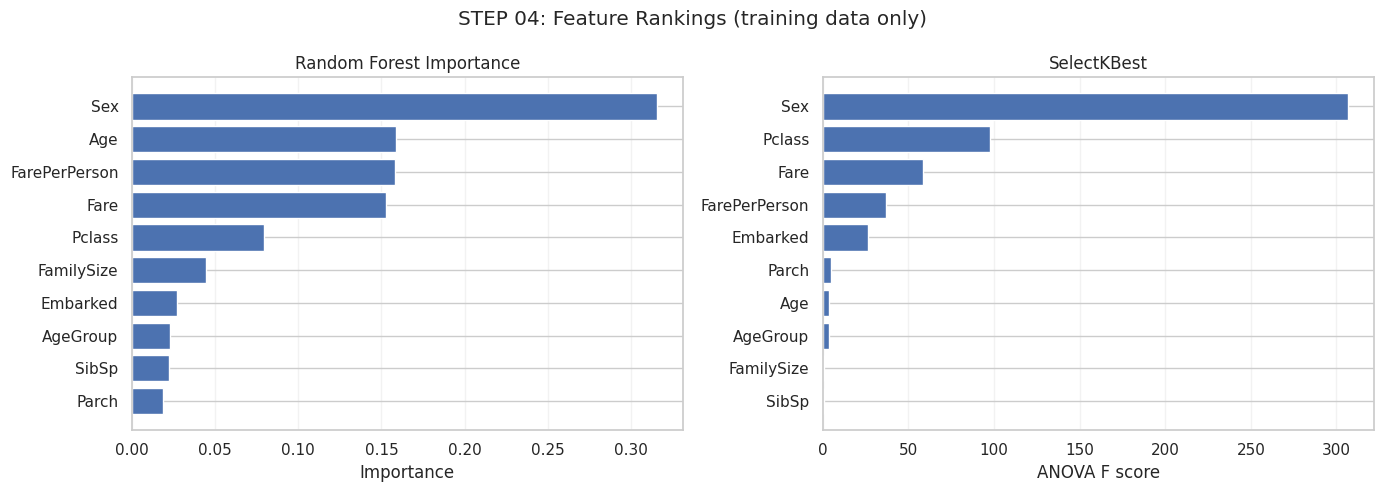

In [ ]:
IMPORTANCE_METHODS = ["Random Forest Importance", "SelectKBest"]
ranking_tables = {}
selected_feature_lists = {}

for method in IMPORTANCE_METHODS:
    model_for_ranking = make_estimator(method, TOP_N)
    model_for_ranking.fit(X_train, y_train)
    preprocessed_names = model_for_ranking.named_steps["preprocess"].get_feature_names_out()
    feature_names = [clean_feature_name(name) for name in preprocessed_names]
    selector = model_for_ranking.named_steps["selector"]

    if method == "Random Forest Importance":
        scores = selector.estimator_.feature_importances_
    else:
        scores = selector.scores_

    rank_df = pd.DataFrame({"Feature": feature_names, "Score": scores})
    rank_df = rank_df.sort_values("Score", ascending=False).reset_index(drop=True)
    rank_df.insert(0, "Rank", range(1, len(rank_df) + 1))
    ranking_tables[method] = rank_df
    selected_feature_lists[method] = [
        feature_names[i] for i, keep in enumerate(selector.get_support()) if keep
    ]
    print(f"\n■ {method}: 상위 {TOP_N}개 선택 변수")
    print(", ".join(rank_df.head(TOP_N)["Feature"].tolist()))
    display(rank_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, IMPORTANCE_METHODS):
    rank_df = ranking_tables[method]
    ax.barh(rank_df["Feature"][::-1], rank_df["Score"][::-1])
    ax.set_title(method)
    ax.set_xlabel("Importance" if method == "Random Forest Importance" else "ANOVA F score")
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("STEP 04: Feature Rankings (training data only)")
plt.tight_layout()
plt.show()

**4. 제거 전·후 성능 비교: 5-Fold 교차검증**

같은 훈련 데이터, 같은 교차검증 폴드, 같은 로지스틱 회귀 모델을 사용합니다.
- 전체 변수 10개 = 기준(Baseline)
- 랜덤포레스트 중요도 상위 3/5/7개
- SelectKBest 상위 3/5/7개
선택 단계가 CV 각 폴드 안에서 다시 적합되므로, 전체 훈련 데이터로 먼저 변수 선택을 해놓고 교차검증하는 오류를 방지합니다. 비교와 최종 후보 선정에는 ROC-AUC 평균을 사용합니다.

In [ ]:
experiments = [("All Features", len(ALL_FEATURES), None)]
for method in IMPORTANCE_METHODS:
    experiments.extend((method, k, method) for k in K_CANDIDATES)

records = []
for label, k, selection_method in experiments:
    estimator = make_estimator(selection_method, k)
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    records.append({
        "Method": label,
        "N_Features": k,
        "CV_Accuracy": np.mean(scores["test_accuracy"]),
        "CV_F1": np.mean(scores["test_f1"]),
        "CV_ROC_AUC": np.mean(scores["test_roc_auc"]),
        "CV_AUC_Std": np.std(scores["test_roc_auc"]),
    })

cv_table = pd.DataFrame(records)
baseline_cv_auc = float(cv_table.loc[cv_table["Method"] == "All Features", "CV_ROC_AUC"].iloc[0])
cv_table["AUC_Change_vs_All"] = cv_table["CV_ROC_AUC"] - baseline_cv_auc

print("■ 전체 변수와 변수 선택 방법의 5-Fold 교차검증 성능 비교")
display(cv_table.round(4))

# 테스트 세트를 보지 않고, 훈련 CV 평균 AUC만으로 최종 선택 후보 결정
selected_only = cv_table[cv_table["Method"] != "All Features"]
best_selected = selected_only.sort_values(
    ["CV_ROC_AUC", "N_Features"], ascending=[False, True]
).iloc[0]
best_method = str(best_selected["Method"])
best_k = int(best_selected["N_Features"])
print(f"최종 변수 선택 후보 (훈련 CV 기준): {best_method}, 상위 {best_k}개")
print(f"해당 후보와 전체 변수 간 CV AUC 차이: {best_selected['AUC_Change_vs_All']:+.4f}")

■ 전체 변수와 변수 선택 방법의 5-Fold 교차검증 성능 비교


,Method,N_Features,CV_Accuracy,CV_F1,CV_ROC_AUC,CV_AUC_Std,AUC_Change_vs_All
0,All Features,10,0.7949,0.7218,0.8511,0.0222,0.0000
1,Random Forest Importance,3,0.7823,0.7107,0.8325,0.0290,-0.0186
2,Random Forest Importance,5,0.7922,0.7249,0.8510,0.0186,-0.0001
3,Random Forest Importance,7,0.7922,0.7210,0.8526,0.0251,0.0014
4,SelectKBest,3,0.7837,0.7100,0.8432,0.0222,-0.0079
5,SelectKBest,5,0.7725,0.7073,0.8443,0.0281,-0.0068
6,SelectKBest,7,0.7865,0.7140,0.8449,0.0235,-0.0062


최종 변수 선택 후보 (훈련 CV 기준): Random Forest Importance, 상위 7개
해당 후보와 전체 변수 간 CV AUC 차이: +0.0014


**5. 성능 비교 그래프**

위 표의 ROC-AUC 평균을 그래프로 표시합니다. 점수가 기준선보다 높으면 변수 선택 후 교차검증 성능이 개선된 것이고, 낮으면 악화된 것입니다. 차이가 매우 작다면 유의미한 개선으로 단정할 수 없습니다.

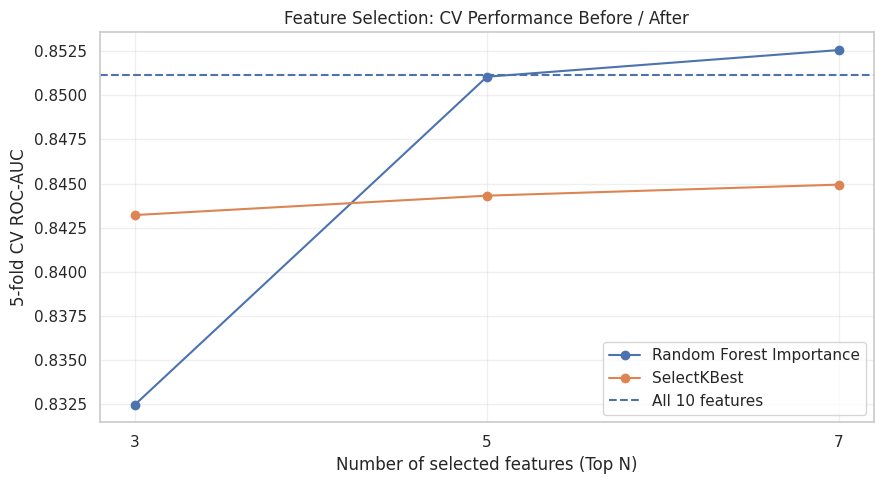

In [ ]:
plt.figure(figsize=(9, 5))
for method in IMPORTANCE_METHODS:
    part = cv_table[cv_table["Method"] == method].sort_values("N_Features")
    plt.plot(part["N_Features"], part["CV_ROC_AUC"], marker="o", label=method)
plt.axhline(baseline_cv_auc, linestyle="--", label="All 10 features")
plt.xticks(K_CANDIDATES)
plt.xlabel("Number of selected features (Top N)")
plt.ylabel("5-fold CV ROC-AUC")
plt.title("Feature Selection: CV Performance Before / After")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**6. 최종 홀드아웃 테스트: 제거 전 vs 선택된 상위 N개**

■ 최종 비교 (20% 홀드아웃 테스트)


,Model,N_Features,Test_Accuracy,Test_F1,Test_ROC_AUC
0,All Features (Before),10,0.7877,0.7031,0.8516
1,Random Forest Importance - Top 7 (After),7,0.7933,0.7132,0.8470


선택된 실제 변수: Age, Fare, FamilySize, FarePerPerson, Pclass, Sex, Embarked
제거된 변수: AgeGroup, Parch, SibSp
테스트 ROC-AUC 변화 (선택-전체): -0.0046


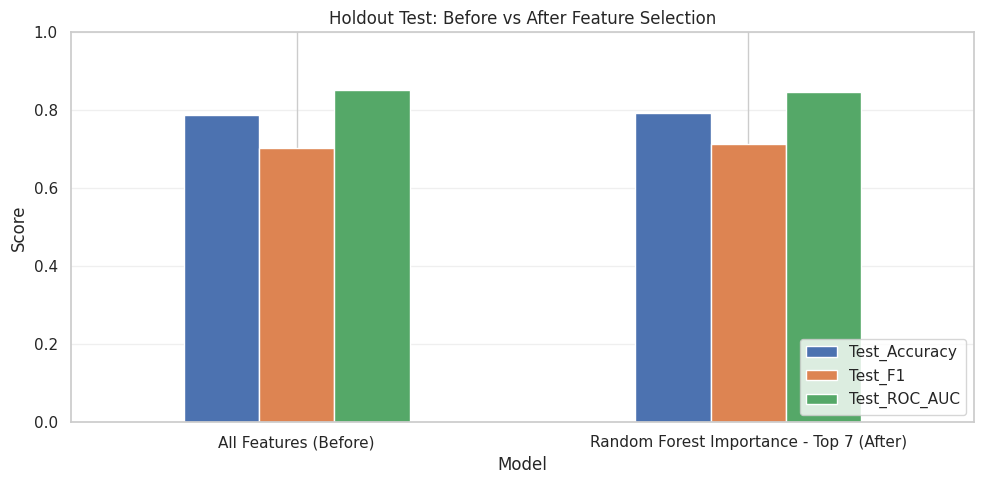

In [ ]:
def evaluate_test(model, name):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "N_Features": len(ALL_FEATURES) if "All Features" in name else best_k,
        "Test_Accuracy": accuracy_score(y_test, pred),
        "Test_F1": f1_score(y_test, pred),
        "Test_ROC_AUC": roc_auc_score(y_test, proba),
    }

baseline_model = make_estimator()
selected_model = make_estimator(best_method, best_k)

holdout_table = pd.DataFrame([
    evaluate_test(baseline_model, "All Features (Before)"),
    evaluate_test(selected_model, f"{best_method} - Top {best_k} (After)"),
])

names = [clean_feature_name(n) for n in selected_model.named_steps["preprocess"].get_feature_names_out()]
selector_mask = selected_model.named_steps["selector"].get_support()
chosen_names = [feature for feature, selected in zip(names, selector_mask) if selected]

print("■ 최종 비교 (20% 홀드아웃 테스트)")
display(holdout_table.round(4))
print("선택된 실제 변수:", ", ".join(chosen_names))
print("제거된 변수:", ", ".join(sorted(set(ALL_FEATURES) - set(chosen_names))))
print("테스트 ROC-AUC 변화 (선택-전체):", round(
    holdout_table.iloc[1]["Test_ROC_AUC"] - holdout_table.iloc[0]["Test_ROC_AUC"], 4
))

plot_data = holdout_table.set_index("Model")[["Test_Accuracy", "Test_F1", "Test_ROC_AUC"]]
ax = plot_data.plot(kind="bar", figsize=(10, 5), rot=0, ylim=(0, 1))
ax.set_ylabel("Score")
ax.set_title("Holdout Test: Before vs After Feature Selection")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**7. 분석 결과**

In [ ]:
before = holdout_table.iloc[0]
after = holdout_table.iloc[1]
cv_delta = float(best_selected["AUC_Change_vs_All"])
test_delta = float(after["Test_ROC_AUC"] - before["Test_ROC_AUC"])

print("=" * 74)
print("STEP 04. 변수 선택 실험 결과 요약")
print("=" * 74)
print(f"1) 데이터: Titanic train.csv, 샘플 {len(df)}개, 타깃 Survived")
print(f"2) 입력 특성: 원본 7개 + 파생 3개 = {len(ALL_FEATURES)}개")
print(f"3) 비교 방법: {', '.join(IMPORTANCE_METHODS)}")
print(f"4) 중요도 상위 N: {K_CANDIDATES}")
print(f"5) 훈련 CV 기준 선택 후보: {best_method}, Top {best_k}")
print(f"6) 선택된 변수: {', '.join(chosen_names)}")
print(f"7) 제거된 변수 수: {len(ALL_FEATURES) - best_k}개")
print(f"8) 교차검증 ROC-AUC: 전체 {baseline_cv_auc:.4f} / 선택 {best_selected['CV_ROC_AUC']:.4f} ({cv_delta:+.4f})")
print(f"9) 테스트 ROC-AUC: 전체 {before['Test_ROC_AUC']:.4f} / 선택 {after['Test_ROC_AUC']:.4f} ({test_delta:+.4f})")
print(f"10) 테스트 Accuracy: 전체 {before['Test_Accuracy']:.4f} / 선택 {after['Test_Accuracy']:.4f}")
print(f"11) 테스트 F1: 전체 {before['Test_F1']:.4f} / 선택 {after['Test_F1']:.4f}")

if cv_delta > 0:
    print("해석: 선택된 변수 모델의 CV ROC-AUC가 전체 변수 모델보다 높았습니다.")
elif cv_delta < 0:
    print("해석: 선택된 변수 모델의 CV ROC-AUC가 전체 변수 모델보다 낮았습니다.")
else:
    print("해석: 교차검증 ROC-AUC는 두 모델이 동일했습니다.")
print("주의: 작은 성능 차이는 표본/분할에 따른 변동일 수 있으며, 변수 중요도는 인과관계를 뜻하지 않습니다.")
print("한계: RF 불순도 중요도는 편향이 가능하며, SelectKBest는 각 특성을 독립 평가합니다.")

cv_table.to_csv("Titanic_STEP04_CV_비교결과.csv", index=False, encoding="utf-8-sig")
holdout_table.to_csv("Titanic_STEP04_테스트_비교결과.csv", index=False, encoding="utf-8-sig")
print("저장 완료: Titanic_STEP04_CV_비교결과.csv, Titanic_STEP04_테스트_비교결과.csv")

STEP 04. 변수 선택 실험 결과 요약
1) 데이터: Titanic train.csv, 샘플 891개, 타깃 Survived
2) 입력 특성: 원본 7개 + 파생 3개 = 10개
3) 비교 방법: Random Forest Importance, SelectKBest
4) 중요도 상위 N: [3, 5, 7]
5) 훈련 CV 기준 선택 후보: Random Forest Importance, Top 7
6) 선택된 변수: Age, Fare, FamilySize, FarePerPerson, Pclass, Sex, Embarked
7) 제거된 변수 수: 3개
8) 교차검증 ROC-AUC: 전체 0.8511 / 선택 0.8526 (+0.0014)
9) 테스트 ROC-AUC: 전체 0.8516 / 선택 0.8470 (-0.0046)
10) 테스트 Accuracy: 전체 0.7877 / 선택 0.7933
11) 테스트 F1: 전체 0.7031 / 선택 0.7132
해석: 선택된 변수 모델의 CV ROC-AUC가 전체 변수 모델보다 높았습니다.
주의: 작은 성능 차이는 표본/분할에 따른 변동일 수 있으며, 변수 중요도는 인과관계를 뜻하지 않습니다.
한계: RF 불순도 중요도는 편향이 가능하며, SelectKBest는 각 특성을 독립 평가합니다.
저장 완료: Titanic_STEP04_CV_비교결과.csv, Titanic_STEP04_테스트_비교결과.csv


# **STEP 05. 모델 학습 및 평가**

In [ ]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

SEED = 42
np.random.seed(SEED)

zip_path = Path("titanic.zip")
if not zip_path.exists() and Path("/mnt/data/titanic.zip").exists():
    zip_path = Path("/mnt/data/titanic.zip")

if not zip_path.exists():
    try:
        from google.colab import files
        print("titanic.zip 파일을 업로드하세요.")
        uploaded = files.upload()
        if "titanic.zip" not in uploaded:
            raise FileNotFoundError("업로드 파일에 titanic.zip이 없습니다.")
        zip_path = Path("titanic.zip")
    except ImportError as exc:
        raise FileNotFoundError("실행 폴더에 titanic.zip을 넣어주세요.") from exc

with zipfile.ZipFile(zip_path) as zf:
    matches = [name for name in zf.namelist() if Path(name).name == "train.csv"]
    if not matches:
        raise FileNotFoundError("ZIP 안에 train.csv가 없습니다.")
    with zf.open(matches[0]) as source:
        df = pd.read_csv(source)

required_cols = [
    "Age", "Fare", "SibSp", "Parch", "Pclass", "Sex", "Embarked", "Survived"
]
if missing := sorted(set(required_cols) - set(df.columns)):
    raise ValueError(f"필수 컬럼 누락: {missing}")

print("데이터 크기:", df.shape)
print("타깃 변수: Survived (0=사망, 1=생존)")
display(df[required_cols].head())
print("타깃 분포:")
display(df["Survived"].value_counts().sort_index().to_frame("Count"))

데이터 크기: (891, 12)
타깃 변수: Survived (0=사망, 1=생존)


,Age,Fare,SibSp,Parch,Pclass,Sex,Embarked,Survived
0,22.0,7.2500,1,0,3,male,S,0
1,38.0,71.2833,1,0,1,female,C,1
2,26.0,7.9250,0,0,3,female,S,1
3,35.0,53.1000,1,0,1,female,S,1
4,35.0,8.0500,0,0,3,male,S,0


타깃 분포:


,Count
Survived,
0,549
1,342


**1. STEP 04와 동일한 7개 변수 사용**

STEP 04의 Random Forest 중요도 실험에서 상위 7개로 선정된 변수는 다음과 같습니다.
- 수치형: Age, Fare, FamilySize, FarePerPerson
- 범주형: Pclass, Sex, Embarked

파생 변수 생성: FamilySize = SibSp + Parch + 1, FarePerPerson = Fare / FamilySize.

분할 조건: random_state=42, 80% 훈련 / 20% 테스트, stratify=y를 사용해 생존/사망 비율 유지. STEP 04와 동일한 분할입니다.

In [ ]:
def make_features(frame):
    result = frame.copy()
    result["FamilySize"] = result["SibSp"] + result["Parch"] + 1
    result["FarePerPerson"] = result["Fare"] / result["FamilySize"]
    return result

NUMERIC_FEATURES = ["Age", "Fare", "FamilySize", "FarePerPerson"]
CATEGORICAL_FEATURES = ["Pclass", "Sex", "Embarked"]
SELECTED_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = make_features(df)[SELECTED_FEATURES].copy()
y = df["Survived"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print("선택된 입력 변수 (7개):", SELECTED_FEATURES)
print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)
print("학습 생존율:", round(y_train.mean(), 4))
print("테스트 생존율:", round(y_test.mean(), 4))
display(X_train.head())

선택된 입력 변수 (7개): ['Age', 'Fare', 'FamilySize', 'FarePerPerson', 'Pclass', 'Sex', 'Embarked']
학습 데이터: (712, 7)
테스트 데이터: (179, 7)
학습 생존율: 0.3834
테스트 생존율: 0.3855


,Age,Fare,FamilySize,FarePerPerson,Pclass,Sex,Embarked
692,NaN,56.4958,1,56.4958,3,male,S
481,NaN,0.0000,1,0.0000,2,male,S
527,NaN,221.7792,1,221.7792,1,male,S
855,18.0,9.3500,2,4.6750,3,female,S
801,31.0,26.2500,3,8.7500,2,female,S


**2. 전처리 파이프라인 및 비교할 모델**

STEP 04의 공통 전처리 설정을 유지합니다.
- 수치형: SimpleImputer(strategy='median') → StandardScaler
- 범주형: SimpleImputer(strategy='most_frequent') → OrdinalEncoder
OrdinalEncoder는 명목형 범주에 임의 순서를 부여할 수 있는 한계가 있습니다. 이번 단계에서는 STEP 04와 비교 조건을 유지하기 위해 동일하게 사용합니다

In [ ]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        (
            "encode",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
        ),
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, NUMERIC_FEATURES),
        ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
    ])


def make_pipeline(classifier):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", classifier),
    ])


MODELS = {
    "Logistic Regression": lambda: LogisticRegression(
        max_iter=2500,
        random_state=SEED,
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=1,
    ),
}

try:
    from xgboost import XGBClassifier

    MODELS["XGBoost"] = lambda: XGBClassifier(
        n_estimators=250,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=SEED,
        n_jobs=1,
    )
except ImportError:
    print("XGBoost 미설치: Logistic Regression과 Random Forest 2개를 비교합니다.")

print("비교 모델:", ", ".join(MODELS))
assert len(MODELS) >= 2, "최소 2개 모델이 필요합니다."

비교 모델: Logistic Regression, Random Forest, XGBoost


**3. 5-Fold 교차검증으로 모델 비교 (훈련 데이터 전용)**

같은 5개 폴드에서 모델 3종의 성능을 비교합니다. 모델 선정 기준은 교차검증 ROC-AUC 평균입니다. 정확도뿐 아니라 생존자를 올바르게 예측하는 능력을 평가하기 위해 Precision, Recall, F1도 함께 기록합니다.

In [ ]:
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_records = []

for name, create_classifier in MODELS.items():
    pipeline = make_pipeline(create_classifier())
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    cv_records.append({
        "Model": name,
        "CV_Accuracy": scores["test_accuracy"].mean(),
        "CV_Precision": scores["test_precision"].mean(),
        "CV_Recall": scores["test_recall"].mean(),
        "CV_F1": scores["test_f1"].mean(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "CV_AUC_Std": scores["test_roc_auc"].std(),
    })

cv_table = (
    pd.DataFrame(cv_records)
    .sort_values("CV_ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

best_model_name = str(cv_table.loc[0, "Model"])
print("■ 5-Fold 교차검증 성능 비교 (훈련 데이터만 이용)")
display(cv_table.round(4))
print("훈련 CV ROC-AUC 기준 선택된 모델:", best_model_name)

■ 5-Fold 교차검증 성능 비교 (훈련 데이터만 이용)


,Model,CV_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,CV_AUC_Std
0,XGBoost,0.8258,0.8006,0.7325,0.7640,0.8904,0.0218
1,Random Forest,0.8188,0.7895,0.7252,0.7546,0.8853,0.0096
2,Logistic Regression,0.7949,0.7522,0.6998,0.7237,0.8534,0.0241


훈련 CV ROC-AUC 기준 선택된 모델: XGBoost


**4. 교차검증 성능 비교 시각화**

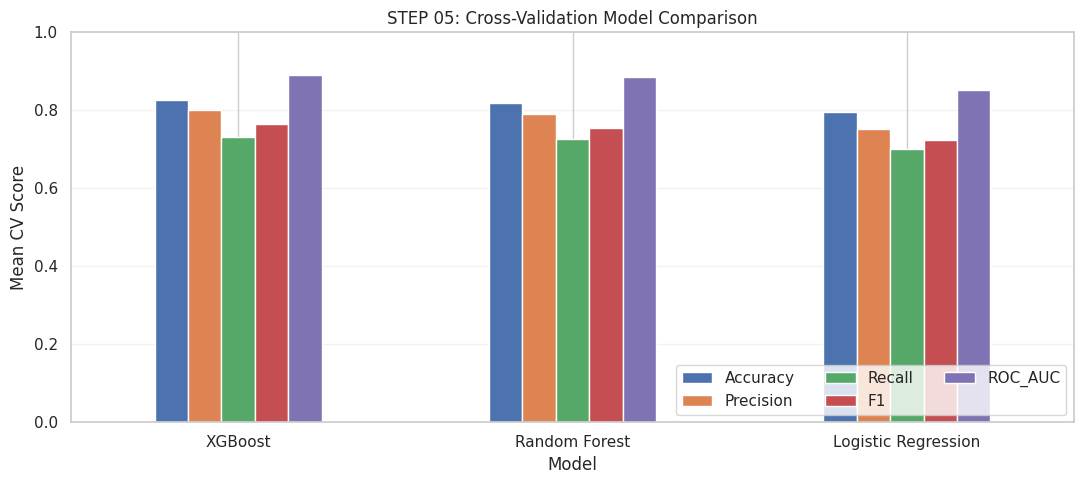

In [ ]:
metric_cols = ["CV_Accuracy", "CV_Precision", "CV_Recall", "CV_F1", "CV_ROC_AUC"]
ax = (
    cv_table.set_index("Model")[metric_cols]
    .rename(columns=lambda c: c.removeprefix("CV_"))
    .plot(kind="bar", figsize=(11, 5), rot=0)
)
ax.set_ylim(0, 1)
ax.set_title("STEP 05: Cross-Validation Model Comparison")
ax.set_ylabel("Mean CV Score")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.show()

**5. 테스트 세트 최종 평가**

모델 3종을 훈련 데이터 전체에서만 적합한 후 공통 테스트 데이터로 평가합니다.
- Accuracy: 전체 예측 중 정답 비율
- Precision: 생존으로 예측한 승객 중 실제 생존 비율
- Recall: 실제 생존 승객 중 생존으로 찾아낸 비율
- F1: Precision과 Recall의 조화평균
- ROC-AUC: 예측 확률을 바탕으로 한 분류 순위 성능

In [ ]:
fitted_models = {}
model_predictions = {}
model_probabilities = {}
test_records = []

for name, create_classifier in MODELS.items():
    pipeline = make_pipeline(create_classifier())
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]

    fitted_models[name] = pipeline
    model_predictions[name] = pred
    model_probabilities[name] = prob
    test_records.append({
        "Model": name,
        "Test_Accuracy": accuracy_score(y_test, pred),
        "Test_Precision": precision_score(y_test, pred, zero_division=0),
        "Test_Recall": recall_score(y_test, pred, zero_division=0),
        "Test_F1": f1_score(y_test, pred, zero_division=0),
        "Test_ROC_AUC": roc_auc_score(y_test, prob),
    })

test_table = pd.DataFrame(test_records)
model_order = cv_table["Model"].tolist()
test_table["Model"] = pd.Categorical(
    test_table["Model"], categories=model_order, ordered=True
)
test_table = test_table.sort_values("Model").reset_index(drop=True)
test_table["Model"] = test_table["Model"].astype(str)

print("■ 테스트 세트 성능 비교 (179명)")
display(test_table.round(4))
print()
print("훈련 CV로 선택한 모델:", best_model_name)
print("해당 모델의 테스트 성능:")
display(test_table[test_table["Model"] == best_model_name].round(4))

■ 테스트 세트 성능 비교 (179명)


,Model,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
0,XGBoost,0.7933,0.7759,0.6522,0.7087,0.8177
1,Random Forest,0.7933,0.7759,0.6522,0.7087,0.8262
2,Logistic Regression,0.7933,0.7667,0.6667,0.7132,0.8470



훈련 CV로 선택한 모델: XGBoost
해당 모델의 테스트 성능:


,Model,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
0,XGBoost,0.7933,0.7759,0.6522,0.7087,0.8177


**6. 혼동행렬(Confusion Matrix) 및 분류 보고서**
- TN: 실제 사망·사망 예측
- FP: 실제 사망·생존 예측
- FN: 실제 생존·사망 예측
- TP: 실제 생존·생존 예측
각 모델의 혼동행렬과 클래스별 Precision / Recall / F1-score를 출력합니다.

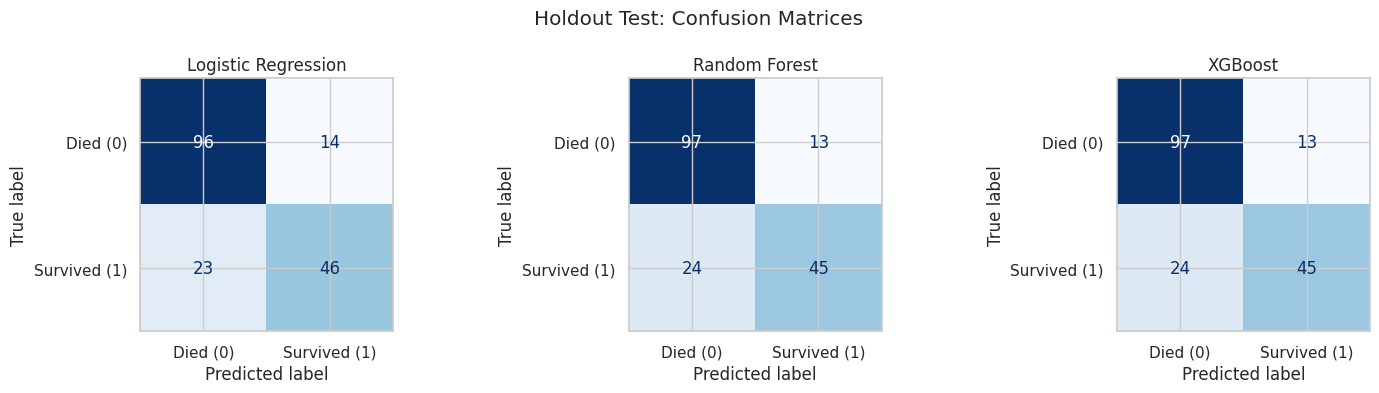

분류 보고서: Logistic Regression
              precision    recall  f1-score   support

    Died (0)       0.81      0.87      0.84       110
Survived (1)       0.77      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179

분류 보고서: Random Forest
              precision    recall  f1-score   support

    Died (0)       0.80      0.88      0.84       110
Survived (1)       0.78      0.65      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.77       179
weighted avg       0.79      0.79      0.79       179

분류 보고서: XGBoost
              precision    recall  f1-score   support

    Died (0)       0.80      0.88      0.84       110
Survived (1)       0.78      0.65      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.77       179
weighted

In [ ]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4))
if len(MODELS) == 1:
    axes = [axes]

for ax, name in zip(axes, MODELS):
    matrix = confusion_matrix(y_test, model_predictions[name], labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Died (0)", "Survived (1)"],
    ).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(name)

plt.suptitle("Holdout Test: Confusion Matrices")
plt.tight_layout()
plt.show()

for name in MODELS:
    print("=" * 70)
    print("분류 보고서:", name)
    print(classification_report(
        y_test,
        model_predictions[name],
        labels=[0, 1],
        target_names=["Died (0)", "Survived (1)"],
        zero_division=0,
    ))

**7. ROC 곡선 비교**

왼쪽 위에 가까운 곡선일수록 긍정적입니다. ROC-AUC가 높을수록 생존자와 사망자를 구분하는 순위 성능이 좋은 경향이 있습니다.

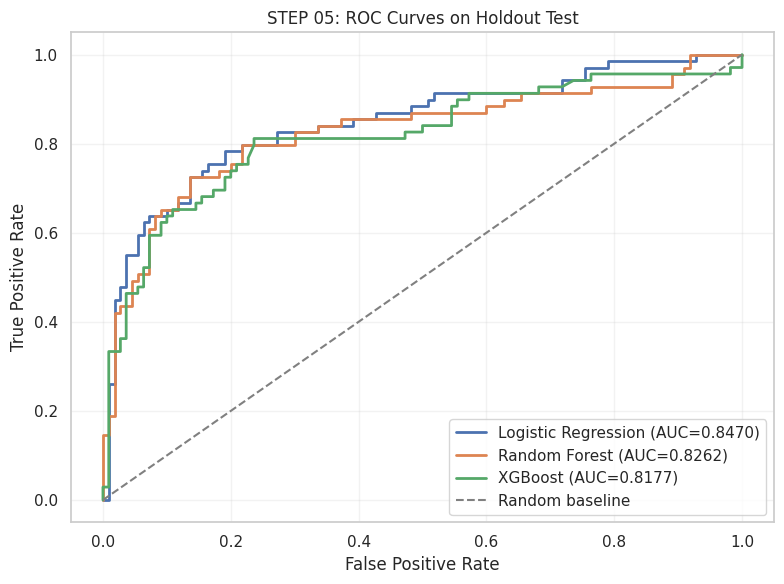

In [ ]:
plt.figure(figsize=(8, 6))
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_test, model_probabilities[name])
    auc = roc_auc_score(y_test, model_probabilities[name])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random baseline")
plt.title("STEP 05: ROC Curves on Holdout Test")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**8. 모델별 변수 중요도 참고**

- Logistic Regression: 표준화된 수치형 변수와 순서형 인코딩된 범주형 변수의 회귀계수 절댓값이 섞여 있습니다. 서로 다른 척도이므로 엄밀한 전체 중요도 순위로 비교할 수 없습니다.
- Random Forest / XGBoost: 모델 내부의 상대적 중요도입니다. 인과관계를 의미하지 않으며, 알고리즘마다 정의가 다릅니다.

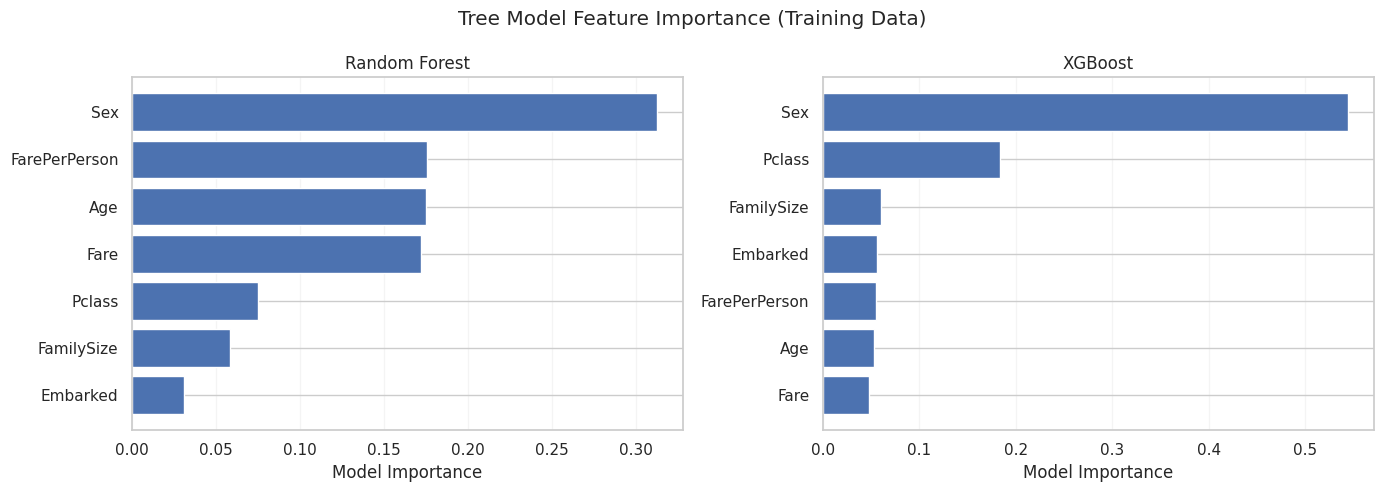

■ Random Forest 변수 중요도


,Feature,Importance
5,Sex,0.3126
3,FarePerPerson,0.1756
0,Age,0.1751
1,Fare,0.1720
4,Pclass,0.0753
2,FamilySize,0.0585
6,Embarked,0.0310


■ XGBoost 변수 중요도


,Feature,Importance
5,Sex,0.5438
4,Pclass,0.1840
2,FamilySize,0.0604
6,Embarked,0.0558
3,FarePerPerson,0.0549
0,Age,0.0529
1,Fare,0.0482


In [ ]:
tree_names = [name for name in MODELS if name in {"Random Forest", "XGBoost"}]
fig, axes = plt.subplots(1, len(tree_names), figsize=(7 * len(tree_names), 5))
if len(tree_names) == 1:
    axes = [axes]

importance_tables = {}
for ax, name in zip(axes, tree_names):
    model = fitted_models[name].named_steps["model"]
    transformer = fitted_models[name].named_steps["preprocess"]
    feature_names = [
        feature.split("__", 1)[-1]
        for feature in transformer.get_feature_names_out()
    ]
    importance_table = pd.DataFrame({
        "Feature": feature_names,
        "Importance": model.feature_importances_,
    }).sort_values("Importance", ascending=False)
    importance_tables[name] = importance_table

    bar_table = importance_table.sort_values("Importance")
    ax.barh(bar_table["Feature"], bar_table["Importance"])
    ax.set_title(name)
    ax.set_xlabel("Model Importance")
    ax.grid(axis="x", alpha=0.2)

plt.suptitle("Tree Model Feature Importance (Training Data)")
plt.tight_layout()
plt.show()

for name, table in importance_tables.items():
    print(f"■ {name} 변수 중요도")
    display(table.round(4))

**9. 결과 분석**

평가 결과를 데이터에서 직접 읽어 요약하므로 재실행 시 점수가 바뀌어도 설명과 숫자가 일치하도록 구성했습니다.

In [ ]:
best_cv_row = cv_table.loc[cv_table["Model"] == best_model_name].iloc[0]
best_test_row = test_table.loc[test_table["Model"] == best_model_name].iloc[0]
most_accurate_test = test_table.loc[test_table["Test_Accuracy"].idxmax(), "Model"]
highest_test_auc = test_table.loc[test_table["Test_ROC_AUC"].idxmax(), "Model"]

print("=" * 76)
print("STEP 05. Titanic 모델 학습 및 평가 결과 요약")
print("=" * 76)
print(f"데이터: Titanic train.csv / 전체 {len(df)}명 / 훈련 {len(X_train)}명 / 테스트 {len(X_test)}명")
print("타깃 변수: Survived (0=사망, 1=생존)")
print("입력 변수 (STEP 04 Top 7):", ", ".join(SELECTED_FEATURES))
print("학습 모델:", ", ".join(MODELS.keys()))
print(f"훈련 CV ROC-AUC 기준 선택 모델: {best_model_name}")
print(f"해당 모델 CV ROC-AUC: {best_cv_row['CV_ROC_AUC']:.4f} (표준편차 {best_cv_row['CV_AUC_Std']:.4f})")
print(f"해당 모델 테스트 Accuracy: {best_test_row['Test_Accuracy']:.4f}")
print(f"해당 모델 테스트 Precision: {best_test_row['Test_Precision']:.4f}")
print(f"해당 모델 테스트 Recall: {best_test_row['Test_Recall']:.4f}")
print(f"해당 모델 테스트 F1: {best_test_row['Test_F1']:.4f}")
print(f"해당 모델 테스트 ROC-AUC: {best_test_row['Test_ROC_AUC']:.4f}")
print(f"테스트 Accuracy 최고: {most_accurate_test}")
print(f"테스트 ROC-AUC 최고: {highest_test_auc}")
print("결론: 훈련 CV ROC-AUC로 모델을 고른 뒤 테스트 결과를 비교했습니다.")
print("한계: STEP 04에서 같은 훈련 분할을 활용해 변수를 선정하였으며,")
print("      소규모 표본 및 한 번의 홀드아웃 평가 결과를 일반화하면 안 됩니다.")

cv_filename = "Titanic_STEP05_CV_모델비교.csv"
test_filename = "Titanic_STEP05_테스트_모델비교.csv"
cv_table.to_csv(cv_filename, index=False, encoding="utf-8-sig")
test_table.to_csv(test_filename, index=False, encoding="utf-8-sig")
print("저장:", cv_filename, "/", test_filename)

STEP 05. Titanic 모델 학습 및 평가 결과 요약
데이터: Titanic train.csv / 전체 891명 / 훈련 712명 / 테스트 179명
타깃 변수: Survived (0=사망, 1=생존)
입력 변수 (STEP 04 Top 7): Age, Fare, FamilySize, FarePerPerson, Pclass, Sex, Embarked
학습 모델: Logistic Regression, Random Forest, XGBoost
훈련 CV ROC-AUC 기준 선택 모델: XGBoost
해당 모델 CV ROC-AUC: 0.8904 (표준편차 0.0218)
해당 모델 테스트 Accuracy: 0.7933
해당 모델 테스트 Precision: 0.7759
해당 모델 테스트 Recall: 0.6522
해당 모델 테스트 F1: 0.7087
해당 모델 테스트 ROC-AUC: 0.8177
테스트 Accuracy 최고: XGBoost
테스트 ROC-AUC 최고: Logistic Regression
결론: 훈련 CV ROC-AUC로 모델을 고른 뒤 테스트 결과를 비교했습니다.
한계: STEP 04에서 같은 훈련 분할을 활용해 변수를 선정하였으며,
      소규모 표본 및 한 번의 홀드아웃 평가 결과를 일반화하면 안 됩니다.
저장: Titanic_STEP05_CV_모델비교.csv / Titanic_STEP05_테스트_모델비교.csv


# **STEP 05. 모델 평가 + 실험 비교**

**STEP 01~04의 Titanic train.csv 데이터 사용, 타깃은 Survived (0=사망, 1=생존)입니다.**

구분	수행 내용

- 성능 평가(3개만 선택)	Accuracy, F1-score, ROC-AUC
- 분류 모델(3개 비교)	Logistic Regression, Random Forest, XGBoost
- 필수 실험 비교	Base / Exp-1 / Exp-2 / Exp-3: 결측치 처리·인코딩·스케일링·변수 선택 조합

- 동일한 무작위 시드(42), 같은 80:20 학습/테스트 분리 및 훈련 데이터 5-Fold 교차검증을 사용합니다.
- STEP 04에서 선택한 원본 7개 변수 Age, Fare, FamilySize, FarePerPerson, Pclass, Sex, Embarked를 사용합니다. (FamilySize, FarePerPerson은 STEP 03 파생 변수)
- 모델/실험 선택은 훈련 데이터의 교차검증 점수로만 결정하고, 테스트 데이터는 성능 보고에 사용합니다.
- 과제 예시의 Label Encoding은 여러 입력 컬럼의 범주를 처리하는 OrdinalEncoder로 구현합니다. LabelEncoder는 주로 타깃 레이블에 사용합니다.

In [ ]:
from pathlib import Path
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    OrdinalEncoder,
    RobustScaler,
    StandardScaler,
)

try:
    from xgboost import XGBClassifier
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'xgboost'])
    from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)

zip_path = Path('titanic.zip')
if not zip_path.exists() and Path('/mnt/data/titanic.zip').exists():
    zip_path = Path('/mnt/data/titanic.zip')

if not zip_path.exists():
    from google.colab import files
    print('titanic.zip 파일을 업로드하세요.')
    uploaded = files.upload()
    if 'titanic.zip' not in uploaded:
        raise FileNotFoundError('titanic.zip을 업로드해야 합니다.')

with zipfile.ZipFile(zip_path) as zf:
    matched = [name for name in zf.namelist() if Path(name).name == 'train.csv']
    if not matched:
        raise FileNotFoundError('ZIP 안에 train.csv가 없습니다.')
    with zf.open(matched[0]) as csv_file:
        df = pd.read_csv(csv_file)

print('원본 데이터 크기:', df.shape)
print('생존 여부 분포:', df['Survived'].value_counts().sort_index().to_dict())
display(df.head(3))

원본 데이터 크기: (891, 12)
생존 여부 분포: {0: 549, 1: 342}


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


**1. STEP 04 선택 변수 + 파생 변수 생성**

파생 변수는 현재 승객의 특성에서만 계산하므로 정답(Survived)은 사용하지 않습니다. 훈련/테스트 분리 후, 모든 학습 가능한 전처리는 Pipeline 안에서 처리해 데이터 누수를 방지합니다.

In [ ]:
def make_features(frame):
    result = frame.copy()
    result['FamilySize'] = result['SibSp'] + result['Parch'] + 1
    result['FarePerPerson'] = result['Fare'] / result['FamilySize']
    return result

NUMERIC_FEATURES = ['Age', 'Fare', 'FamilySize', 'FarePerPerson']
CATEGORICAL_FEATURES = ['Pclass', 'Sex', 'Embarked']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = make_features(df)[FEATURES].copy()
y = df['Survived'].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc'}

print('선택 변수:', FEATURES)
print('훈련:', X_train.shape, '테스트:', X_test.shape)
print('훈련 데이터 누락값:')
display(X_train.isna().sum().to_frame('Missing count'))

선택 변수: ['Age', 'Fare', 'FamilySize', 'FarePerPerson', 'Pclass', 'Sex', 'Embarked']
훈련: (712, 7) 테스트: (179, 7)
훈련 데이터 누락값:


,Missing count
Age,137
Fare,0
FamilySize,0
FarePerPerson,0
Pclass,0
Sex,0
Embarked,2


**2. 성능 평가: 분류 모델 3개 비교**

STEP 05에서 사용한 모델 조합을 그대로 유지합니다. 모델별 전처리 조건을 Median + Ordinal(레이블형) + StandardScaler + 변수 선택 없음으로 통일합니다.
- Accuracy: 전체 샘플 중 맞힌 비율
- F1-score: 생존(1)에 대한 정밀도와 재현율의 조화평균
- ROC-AUC: 임계값 전반에서 생존/사망을 구분하는 확률 순위 능력

In [ ]:
def common_preprocessor():
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), NUMERIC_FEATURES),
        ('category', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1,
            )),
        ]), CATEGORICAL_FEATURES),
    ])

MODEL_FACTORIES = {
    'Logistic Regression': lambda: LogisticRegression(
        max_iter=2500,
        random_state=SEED,
    ),
    'Random Forest': lambda: RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=1,
    ),
    'XGBoost': lambda: XGBClassifier(
        n_estimators=250,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=SEED,
        n_jobs=1,
    ),
}

model_cv_records = []
model_test_records = []

for name, factory in MODEL_FACTORIES.items():
    estimator = Pipeline([
        ('preprocess', common_preprocessor()),
        ('model', factory()),
    ])
    cv_scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring=SCORING, n_jobs=1, error_score='raise',
    )
    model_cv_records.append({
        'Model': name,
        'CV_Accuracy': cv_scores['test_accuracy'].mean(),
        'CV_F1': cv_scores['test_f1'].mean(),
        'CV_ROC_AUC': cv_scores['test_roc_auc'].mean(),
    })

    estimator.fit(X_train, y_train)
    predicted = estimator.predict(X_test)
    probability = estimator.predict_proba(X_test)[:, 1]
    model_test_records.append({
        'Model': name,
        'Test_Accuracy': accuracy_score(y_test, predicted),
        'Test_F1': f1_score(y_test, predicted),
        'Test_ROC_AUC': roc_auc_score(y_test, probability),
    })

model_cv_table = pd.DataFrame(model_cv_records).sort_values(
    'CV_ROC_AUC', ascending=False
).reset_index(drop=True)
model_test_table = pd.DataFrame(model_test_records)

print('■ 훈련 데이터 5-Fold 교차검증')
display(model_cv_table.round(4))
print('■ 홀드아웃 테스트 결과 (모델 선정에는 사용하지 않음)')
display(model_test_table.round(4))
print('훈련 CV ROC-AUC 기준 최상위 모델:', model_cv_table.iloc[0]['Model'])

■ 훈련 데이터 5-Fold 교차검증


,Model,CV_Accuracy,CV_F1,CV_ROC_AUC
0,XGBoost,0.8258,0.7640,0.8904
1,Random Forest,0.8188,0.7546,0.8853
2,Logistic Regression,0.7949,0.7237,0.8534


■ 홀드아웃 테스트 결과 (모델 선정에는 사용하지 않음)


,Model,Test_Accuracy,Test_F1,Test_ROC_AUC
0,Logistic Regression,0.7933,0.7132,0.8470
1,Random Forest,0.7933,0.7087,0.8262
2,XGBoost,0.7933,0.7087,0.8177


훈련 CV ROC-AUC 기준 최상위 모델: XGBoost


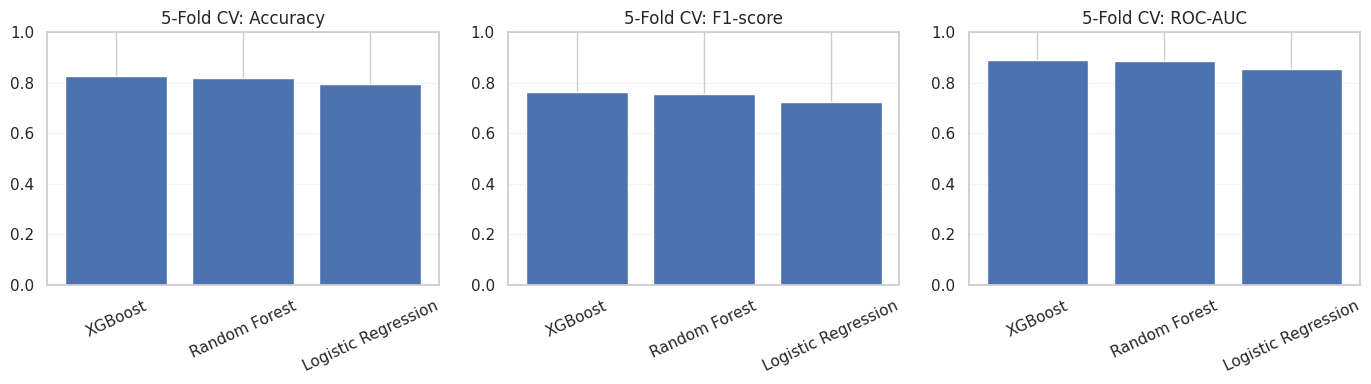

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
metrics = [('CV_Accuracy', 'Accuracy'), ('CV_F1', 'F1-score'), ('CV_ROC_AUC', 'ROC-AUC')]
for ax, (column, title) in zip(axes, metrics):
    ax.bar(model_cv_table['Model'], model_cv_table[column])
    ax.set_title(f'5-Fold CV: {title}')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', labelrotation=25)
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

**3. 필수 실험 비교 — Base / Exp-1 / Exp-2 / Exp-3**

| 실험 | 결측치 처리 | 인코딩 | 스케일링 | Feature Selection |
|---|---|---|---|---|
| **Base** | 없음 | 없음 | 없음 | 없음 |
| **Exp-1** | Mean | One-Hot | StandardScaler | X |
| **Exp-2** | Median | Label(Ordinal) | MinMaxScaler | O (SelectKBest 5개) |
| **Exp-3** | Most Frequent | One-Hot | RobustScaler | O (SelectKBest 5개) |

비교의 공정성: 4개 실험 모두 XGBoost 분류기, 동일한 7개 원본 입력 변수, 같은 훈련 데이터와 5-Fold CV를 사용합니다.

Base 해석의 주의점: 원본 데이터에 문자열 범주와 결측값이 존재하므로 일반 Logistic Regression은 아무런 전처리 없이 학습할 수 없습니다. 따라서 Base에서는 결측값과 범주를 자체 지원하는 XGBoost를 사용하고, Pclass, Sex, Embarked를 Pandas category 자료형으로만 지정합니다. 이 과정은 원-핫/정수 인코딩이나 외부 결측값 대체가 아닙니다. Base의 결측값은 모델 내부에서 처리합니다. 이는 '알고리즘이 결측에 아무 영향도 받지 않는다'는 의미가 아닙니다.
- 실험별 결측치 처리 이름은 수치형 특성의 대체 전략이며, 범주형 결측치는 Exp-1~3 모두 최빈값으로 대체합니다.
- Feature Selection O는 인코딩을 마친 변환된 컬럼 중 상위 5개를 SelectKBest로 고르는 방식입니다.
- 트리 기반 XGBoost는 수치 스케일링에 덜 민감하므로, 결과 차이가 작거나 없을 수 있습니다.

In [ ]:
def xgb_for_experiment():
    return XGBClassifier(
        n_estimators=140,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective='binary:logistic',
        eval_metric='logloss',
        enable_categorical=True,
        tree_method='hist',
        random_state=SEED,
        n_jobs=1,
    )

EXPERIMENT_CONFIGS = {
    'Base': {'missing': '없음', 'encoding': '없음', 'scaling': '없음', 'selection': '없음'},
    'Exp-1': {'missing': 'Mean', 'encoding': 'One-Hot', 'scaling': 'StandardScaler', 'selection': 'X'},
    'Exp-2': {'missing': 'Median', 'encoding': 'Label', 'scaling': 'MinMaxScaler', 'selection': 'O'},
    'Exp-3': {'missing': 'Most Frequent', 'encoding': 'One-Hot', 'scaling': 'RobustScaler', 'selection': 'O'},
}


def xgb_input(frame):
    """Base 실험의 원본 범주형 변수는 native category dtype으로만 지정합니다."""
    result = frame.copy()
    for column in CATEGORICAL_FEATURES:
        result[column] = result[column].astype('category')
    return result


def experiment_preprocessor(config):
    impute_strategy = {
        'Mean': 'mean',
        'Median': 'median',
        'Most Frequent': 'most_frequent',
    }[config['missing']]
    scaler_type = {
        'StandardScaler': StandardScaler,
        'MinMaxScaler': MinMaxScaler,
        'RobustScaler': RobustScaler,
    }[config['scaling']]

    if config['encoding'] == 'One-Hot':
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    else:
        encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy=impute_strategy)),
            ('scale', scaler_type()),
        ]), NUMERIC_FEATURES),
        ('category', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encode', encoder),
        ]), CATEGORICAL_FEATURES),
    ], sparse_threshold=0)


def build_experiment(experiment_name):
    if experiment_name == 'Base':
        # 모든 전처리 단계 생략. 내부 결측/범주 지원 XGBoost 이용.
        return Pipeline([('model', xgb_for_experiment())])

    config = EXPERIMENT_CONFIGS[experiment_name]
    selector = SelectKBest(score_func=f_classif, k=5) if config['selection'] == 'O' else 'passthrough'

    return Pipeline([
        ('preprocess', experiment_preprocessor(config)),
        ('select', selector),
        ('model', xgb_for_experiment()),
    ])

X_train_native = xgb_input(X_train)
X_test_native = xgb_input(X_test)

experiment_records = []
for name, config in EXPERIMENT_CONFIGS.items():
    estimator = build_experiment(name)
    scores = cross_validate(
        estimator,
        X_train_native, y_train,
        cv=cv, scoring=SCORING,
        n_jobs=1, error_score='raise',
    )
    experiment_records.append({
        '실험': name,
        '결측치 처리': config['missing'],
        '인코딩': config['encoding'],
        '스케일링': config['scaling'],
        'Feature Selection': config['selection'],
        'CV_Accuracy': scores['test_accuracy'].mean(),
        'CV_F1': scores['test_f1'].mean(),
        'CV_ROC_AUC': scores['test_roc_auc'].mean(),
    })

experiment_table = pd.DataFrame(experiment_records)
best_experiment_name = str(experiment_table.loc[experiment_table['CV_ROC_AUC'].idxmax(), '실험'])
print('■ 실험 조합별 비교표 (훈련 데이터 5-Fold CV)')
display(experiment_table.round(4))
print('훈련 CV ROC-AUC 기준 최상위 조합:', best_experiment_name)

■ 실험 조합별 비교표 (훈련 데이터 5-Fold CV)


,실험,결측치 처리,인코딩,스케일링,Feature Selection,CV_Accuracy,CV_F1,CV_ROC_AUC
0,Base,없음,없음,없음,없음,0.8244,0.7601,0.8881
1,Exp-1,Mean,One-Hot,StandardScaler,X,0.8259,0.7615,0.8870
2,Exp-2,Median,Label,MinMaxScaler,O,0.7992,0.7166,0.8716
3,Exp-3,Most Frequent,One-Hot,RobustScaler,O,0.8133,0.7316,0.8585


훈련 CV ROC-AUC 기준 최상위 조합: Base


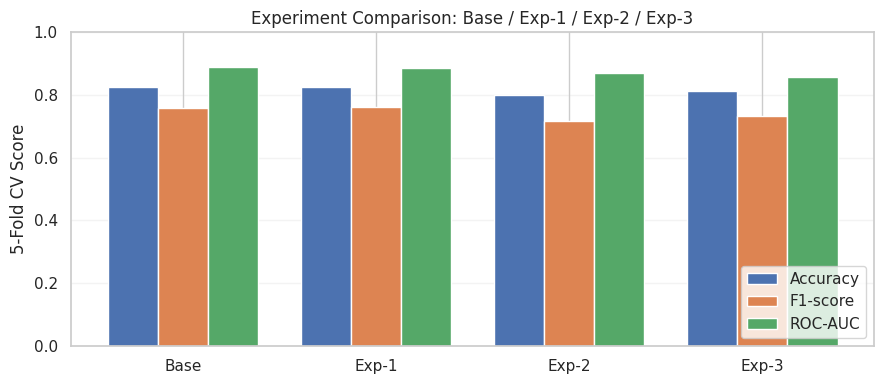

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(len(experiment_table))
bar_width = 0.26
for i, (column, label) in enumerate([
    ('CV_Accuracy', 'Accuracy'),
    ('CV_F1', 'F1-score'),
    ('CV_ROC_AUC', 'ROC-AUC'),
]):
    ax.bar(positions + (i - 1) * bar_width, experiment_table[column],
           width=bar_width, label=label)
ax.set_xticks(positions, experiment_table['실험'])
ax.set_ylim(0, 1)
ax.set_ylabel('5-Fold CV Score')
ax.set_title('Experiment Comparison: Base / Exp-1 / Exp-2 / Exp-3')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.22)
plt.tight_layout()
plt.show()

**4. ① Pipeline 객체 활용**

위의 모든 전처리 조합은 Pipeline / ColumnTransformer로 묶여 있습니다. 실제 코드의 preprocess → select → model 구조를 출력하고, 학습/교차검증 과정에서 단계별 학습이 각 Fold 안에서만 수행되게 했습니다.

In [ ]:
for name in EXPERIMENT_CONFIGS:
    estimator = build_experiment(name)
    print(f'{name}: {list(estimator.named_steps)}')
print('\n선택된 실험의 Pipeline:')
print(build_experiment(best_experiment_name))

Base: ['model']
Exp-1: ['preprocess', 'select', 'model']
Exp-2: ['preprocess', 'select', 'model']
Exp-3: ['preprocess', 'select', 'model']

선택된 실험의 Pipeline:
Pipeline(steps=[('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.9, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3,

**5. ② GridSearchCV 적용**

앞에서 훈련 CV 성능으로 선정한 실험 조합에 대해서만 XGBoost 하이퍼파라미터를 탐색합니다.
- 탐색값: n_estimators = [100, 180], max_depth = [2, 3], learning_rate = [0.05, 0.1]
- 총 8가지 조합 × 5-Fold를 훈련 데이터에서만 검증합니다.
- 최적 파라미터 선택 기준: ROC-AUC. 홀드아웃 테스트 점수를 보고 파라미터를 바꾸지 않습니다.

In [ ]:
grid = GridSearchCV(
    estimator=build_experiment(best_experiment_name),
    param_grid={
        'model__n_estimators': [100, 180],
        'model__max_depth': [2, 3],
        'model__learning_rate': [0.05, 0.1],
    },
    scoring='roc_auc',
    cv=cv,
    n_jobs=1,
    refit=True,
    error_score='raise',
)
grid.fit(X_train_native, y_train)
print('GridSearchCV 최적 파라미터:', grid.best_params_)
print('GridSearchCV 최고 훈련 CV ROC-AUC:', round(grid.best_score_, 4))

grid_summary = pd.DataFrame(grid.cv_results_)[[
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__learning_rate',
    'mean_test_score',
    'std_test_score',
    'rank_test_score',
]].sort_values(['rank_test_score', 'mean_test_score'], ascending=[True, False])
display(grid_summary.head(8).round(4))

GridSearchCV 최적 파라미터: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 180}
GridSearchCV 최고 훈련 CV ROC-AUC: 0.888


,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,mean_test_score,std_test_score,rank_test_score
3,180,3,0.05,0.8880,0.0234,1
1,180,2,0.05,0.8870,0.0226,2
2,100,3,0.05,0.8859,0.0237,3
0,100,2,0.05,0.8845,0.0221,4
5,180,2,0.10,0.8843,0.0196,5
6,100,3,0.10,0.8839,0.0212,6
7,180,3,0.10,0.8829,0.0168,7
4,100,2,0.10,0.8813,0.0220,8


**6. 최종 테스트 — Base / 선택 조합 / GridSearchCV 튜닝 결과**

In [ ]:
def test_scores(model, x_values, label):
    y_pred = model.predict(x_values)
    y_prob = model.predict_proba(x_values)[:, 1]
    return {
        '설정': label,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
    }

base_model = build_experiment('Base')
base_model.fit(X_train_native, y_train)

best_untuned_model = build_experiment(best_experiment_name)
best_untuned_model.fit(X_train_native, y_train)

final_model = grid.best_estimator_
final_test_table = pd.DataFrame([
    test_scores(base_model, X_test_native, 'Base'),
    test_scores(best_untuned_model, X_test_native, f'{best_experiment_name} (untuned)'),
    test_scores(final_model, X_test_native, f'{best_experiment_name} + GridSearchCV'),
])
print('■ 동일 테스트셋 179명 평가')
display(final_test_table.round(4))

■ 동일 테스트셋 179명 평가


,설정,Accuracy,F1-score,ROC-AUC
0,Base,0.7877,0.7031,0.8244
1,Base (untuned),0.7877,0.7031,0.8244
2,Base + GridSearchCV,0.7877,0.7031,0.8211


**7. ③ Feature Importance 시각화 고도화**

■ Permutation Feature Importance


,Feature,Mean_AUC_Drop,Std_AUC_Drop
5,Sex,0.2218,0.0486
4,Pclass,0.0292,0.0076
3,FarePerPerson,0.0268,0.0162
2,FamilySize,0.0215,0.0055
0,Age,0.0199,0.0078
6,Embarked,-0.0005,0.0069
1,Fare,-0.0091,0.0078


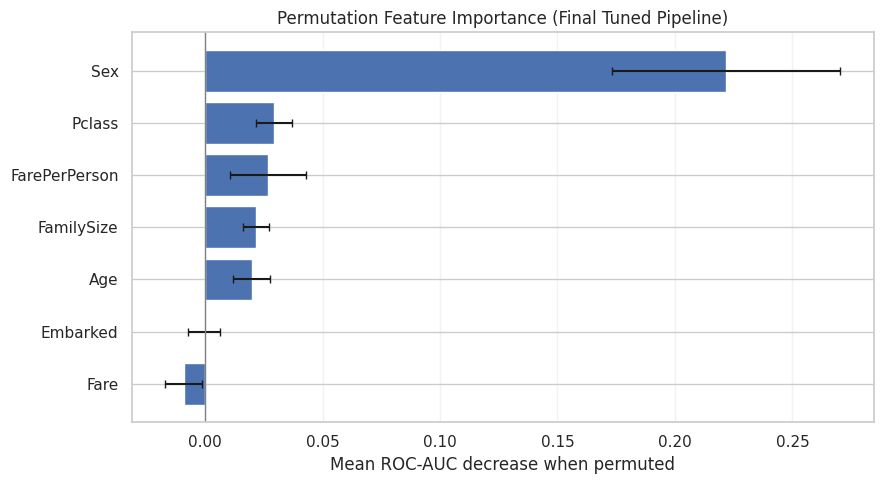

In [ ]:
importance = permutation_importance(
    final_model,
    X_test_native,
    y_test,
    scoring='roc_auc',
    n_repeats=12,
    random_state=SEED,
    n_jobs=1,
)
importance_table = pd.DataFrame({
    'Feature': FEATURES,
    'Mean_AUC_Drop': importance.importances_mean,
    'Std_AUC_Drop': importance.importances_std,
}).sort_values('Mean_AUC_Drop', ascending=False)
print('■ Permutation Feature Importance')
display(importance_table.round(4))

plot_table = importance_table.sort_values('Mean_AUC_Drop')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    plot_table['Feature'],
    plot_table['Mean_AUC_Drop'],
    xerr=plot_table['Std_AUC_Drop'],
    capsize=3,
)
ax.axvline(0, color='gray', linewidth=1)
ax.set_xlabel('Mean ROC-AUC decrease when permuted')
ax.set_title('Permutation Feature Importance (Final Tuned Pipeline)')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

**8. 실험 결과 요약**

In [ ]:
print('=' * 70)
print('STEP 05. 모델 학습 및 실험 비교 종합 결과')
print('=' * 70)
print('데이터: Titanic train.csv / 전체:', len(df), '학습:', len(X_train), '테스트:', len(X_test))
print('지표: Accuracy / F1-score / ROC-AUC')
print('모델 비교(훈련 CV 최상위):', model_cv_table.loc[0, 'Model'])
print('실험 조합(훈련 CV 최상위):', best_experiment_name)
print('해당 조합 CV ROC-AUC:', round(experiment_table['CV_ROC_AUC'].max(), 4))
print('GridSearchCV 최고 CV ROC-AUC:', round(grid.best_score_, 4))
print('최종 튜닝 모델 테스트 ROC-AUC:', round(final_test_table.iloc[-1]['ROC-AUC'], 4))
print('상위 Permutation 중요도:', importance_table.iloc[0]['Feature'])

model_cv_table.to_csv('Titanic_STEP05_모델_CV_성능.csv', index=False, encoding='utf-8-sig')
model_test_table.to_csv('Titanic_STEP05_모델_테스트_성능.csv', index=False, encoding='utf-8-sig')
experiment_table.to_csv('Titanic_STEP05_실험비교표.csv', index=False, encoding='utf-8-sig')
final_test_table.to_csv('Titanic_STEP05_최종테스트.csv', index=False, encoding='utf-8-sig')
importance_table.to_csv('Titanic_STEP05_변수중요도.csv', index=False, encoding='utf-8-sig')
print('CSV 파일 5개 저장 완료')

STEP 05. 모델 학습 및 실험 비교 종합 결과
데이터: Titanic train.csv / 전체: 891 학습: 712 테스트: 179
지표: Accuracy / F1-score / ROC-AUC
모델 비교(훈련 CV 최상위): XGBoost
실험 조합(훈련 CV 최상위): Base
해당 조합 CV ROC-AUC: 0.8881
GridSearchCV 최고 CV ROC-AUC: 0.888
최종 튜닝 모델 테스트 ROC-AUC: 0.8211
상위 Permutation 중요도: Sex
CSV 파일 5개 저장 완료
